# NimbusPay ticket triage: LoRA fine-tune of Qwen2.5-3B-Instruct

Pipeline: setup, data audit and cleaning, sequence length analysis, baselines, training, controlled experiments, error analysis, final model and test predictions.

Runs on a free Colab T4. Every run saves its adapter, logs and predictions to Google Drive under `MyDrive/nimbus_triage/runs/`.

## 0. Setup

Pinned library versions, seeds, paths and shared helpers. On Colab the data is read from `MyDrive/nimbus_triage/candidate_pack/`; locally it is read from `./candidate_pack/`.

In [1]:
import os
import sys
import subprocess
from importlib.metadata import version, PackageNotFoundError

IN_COLAB = "google.colab" in sys.modules

PINS = {
    "transformers": "5.22.1",
    "peft": "0.21.2",
    "accelerate": "1.15.0",
    "bitsandbytes": "0.50.2",
}
EXPECTED_TORCH = "2.14.1"


def installed(pkg):
    try:
        return version(pkg)
    except PackageNotFoundError:
        return None


if IN_COLAB:
    missing = [f"{p}=={v}" for p, v in PINS.items() if installed(p) != v]
    if missing:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
    if installed("torchao"):
        subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchao"], check=True)

print("colab:", IN_COLAB)
print(f"torch=={installed('torch')}", "" if (installed("torch") or "").startswith(EXPECTED_TORCH) else f"(expected {EXPECTED_TORCH})")
for pkg, want in PINS.items():
    have = installed(pkg)
    print(f"{pkg}=={have}", "" if have == want else f"(expected {want})")
print("torchao:", installed("torchao") or "not installed (Colab's preinstalled 0.10 breaks peft's LoRA layer dispatch)")

colab: True
torch==2.14.1+cu130 
transformers==5.22.1 
peft==0.21.2 
accelerate==1.15.0 
bitsandbytes==0.50.2 
torchao: not installed (Colab's preinstalled 0.10 breaks peft's LoRA layer dispatch)


In [2]:
import csv
import json
import random
import time
import importlib.util
from datetime import datetime
from pathlib import Path

import numpy as np

NOTEBOOK_START = time.time()

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/nimbus_triage")
else:
    ROOT = Path.cwd()

PACK = ROOT / "candidate_pack"
DATA = PACK / "data"
RUNS = ROOT / "runs"
RESULTS = ROOT / "results"
for d in (RUNS, RESULTS):
    d.mkdir(parents=True, exist_ok=True)

BASE_MODEL = "Qwen/Qwen2.5-3B-Instruct"
SEED = 42
MAX_NEW_TOKENS = 200

KEYS = ["category", "priority", "amount_paise", "txn_date", "txn_id", "channel", "language", "needs_human"]
CATEGORIES = ["payment_failed", "refund", "fraud", "account_access", "kyc", "offers", "other"]
PRIORITIES = ["P1", "P2", "P3"]
CHANNELS = ["upi", "card", "netbanking", "wallet"]
LANGUAGES = ["en", "hi-en"]
SOURCES = ["app-chat", "email", "twitter", "ivr-transcript"]
TXN_FIELDS = ["amount_paise", "txn_date", "txn_id", "channel"]
NON_TXN_CATEGORIES = ["account_access", "kyc", "other"]

for p in [DATA / "train.jsonl", DATA / "dev.jsonl", DATA / "test_inputs.jsonl", PACK / "score.py", PACK / "SCHEMA.md"]:
    assert p.exists(), f"missing {p}"

print("root:", ROOT)
print("runs (adapters, large files):", RUNS)
print("results (small files committed to the repo):", RESULTS)

Mounted at /content/drive
root: /content/drive/MyDrive/nimbus_triage
runs (adapters, large files): /content/drive/MyDrive/nimbus_triage/runs
results (small files committed to the repo): /content/drive/MyDrive/nimbus_triage/results


In [3]:
def load_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def save_jsonl(rows, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")


def system_text(row):
    return row["messages"][0]["content"]


def user_text(row):
    return row["messages"][1]["content"]


def label_text(row):
    return row["messages"][2]["content"]


def ticket_body(row):
    return user_text(row).split("\n\n", 1)[-1]


def received_date(row):
    return datetime.strptime(user_text(row).split("\n", 1)[0].split()[1], "%Y-%m-%d").date()


def ticket_source(row):
    return user_text(row).split("\n")[1].split(": ", 1)[1].strip()


def canonical(label):
    return json.dumps({k: label[k] for k in KEYS}, ensure_ascii=False)


_spec = importlib.util.spec_from_file_location("nimbus_score", PACK / "score.py")
scorer = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(scorer)


def evaluate(gold_rows, pred_rows):
    return scorer.score(gold_rows, pred_rows)


def show_scores(res, prefixes=None):
    print(f"{'group':28} {'n':>5} {'valid':>7} {'exact':>7} {'fields':>7}")
    for name in sorted(res, key=lambda x: (x != "all", x)):
        if prefixes is not None and name != "all" and not name.startswith(tuple(prefixes)):
            continue
        r = res[name]
        print(f"{name:28} {r['n']:5d} {r['json_valid']:7.1%} {r['exact_match']:7.1%} {r['mean_field_acc']:7.1%}")
    print("per-field accuracy:", {k: round(v, 3) for k, v in res["all"]["fields"].items()})


EXPERIMENTS_CSV = RESULTS / "experiments.csv"
EXPERIMENT_COLUMNS = ["run", "change", "train_rows", "dev_exact", "dev_field_acc", "dev_json_valid",
                      "stress_exact", "stress_field_acc",
                      "peak_gpu_gb", "train_minutes", "trainable_params", "timestamp"]


def log_experiment(record):
    record = {**record, "timestamp": datetime.now().isoformat(timespec="seconds")}
    rows = []
    if EXPERIMENTS_CSV.exists():
        with open(EXPERIMENTS_CSV, newline="", encoding="utf-8") as f:
            rows = list(csv.DictReader(f))
    old = next((r for r in rows if r["run"] == record["run"]), {})
    record = {**old, **record}
    rows = [r for r in rows if r["run"] != record["run"]]
    EXPERIMENTS_CSV.parent.mkdir(parents=True, exist_ok=True)
    with open(EXPERIMENTS_CSV, "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=EXPERIMENT_COLUMNS, extrasaction="ignore")
        w.writeheader()
        w.writerows(rows + [record])
    return record


train_raw = load_jsonl(DATA / "train.jsonl")
dev = load_jsonl(DATA / "dev.jsonl")
test = load_jsonl(DATA / "test_inputs.jsonl")
print(len(train_raw), len(dev), len(test))
print(user_text(dev[0]))
print(label_text(dev[0]))

1445 200 400
Received: 2026-08-28 (Fri)
Source: app-chat

Good morning, What needs to be done to activate and use a card? My earlier ticket number is #54047. Please look into it.
{"category": "other", "priority": "P3", "amount_paise": null, "txn_date": null, "txn_id": null, "channel": null, "language": "en", "needs_human": false}


In [4]:
import torch
import transformers


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    transformers.set_seed(seed)


set_seed()

print("python", sys.version.split()[0], "| torch", torch.__version__, "| transformers", transformers.__version__)
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    NATIVE_BF16 = props.major >= 8
    print("gpu:", props.name, f"{props.total_memory / 1e9:.1f} GB", f"| compute capability {props.major}.{props.minor}",
          "| native bf16:", NATIVE_BF16, "| training dtype:", "bf16" if NATIVE_BF16 else "fp16")
else:
    print("gpu: none")

python 3.13.16 | torch 2.14.1+cu130 | transformers 5.22.1
gpu: Tesla T4 15.6 GB | compute capability 7.5 | native bf16: False | training dtype: fp16


## 1. Part A: data audit

The training labels came out of a noisy pipeline. The audit has three layers:

1. **Structure**: the label must parse as JSON, have the 8 spec keys, use the right types and formats, not repeat dev or test tickets, and not be a duplicate or a junk ticket.
2. **Rules**: a reference labeller written only from `SCHEMA.md` and the phrasing seen in `train.jsonl` reads each ticket and works out the fields the spec defines mechanically (priority, needs_human, txn_id, amount, date, channel). Every disagreement with the given label is a finding.
3. **Consistency**: tickets that open with the same issue sentence should share a category and a language. Rows that go against their group are flagged.

The reference labeller is only an audit tool. It is never used at inference. It was built from train only. Dev is used once at the end to measure how accurate the labeller is, not to tune it.

In [5]:
import re
from collections import Counter, defaultdict

import pandas as pd

FIXED_SYSTEM = system_text(dev[0])
findings = defaultdict(set)


def flag(code, rid):
    findings[code].add(rid)


def parse_label(text):
    try:
        obj = json.loads(text)
    except json.JSONDecodeError:
        return None
    return obj if isinstance(obj, dict) else None


def norm_text(s):
    return re.sub(r"\s+", " ", s).strip().lower()


ISO_DATE = re.compile(r"\d{4}-\d{2}-\d{2}")
DMY_DATE = re.compile(r"(\d{2})/(\d{2})/(\d{4})")
TXN_ID = re.compile(r"NP\d{10}")

labels = {}
for r in train_raw:
    rid = r["id"]
    if [m["role"] for m in r["messages"]] != ["system", "user", "assistant"]:
        flag("bad_roles", rid)
    if system_text(r) != FIXED_SYSTEM:
        flag("bad_system_prompt", rid)
    y = parse_label(label_text(r))
    if y is None:
        flag("label_not_json", rid)
        continue
    labels[rid] = y
    if "prio" in y:
        flag("schema_v1_prio_key", rid)
    elif set(y) != set(KEYS):
        flag("wrong_keys", rid)
    if y.get("category") not in CATEGORIES:
        flag("bad_category_value", rid)
    if "priority" in y and y["priority"] not in PRIORITIES:
        flag("bad_priority_value", rid)
    a = y.get("amount_paise")
    if a is not None and type(a) is not int:
        flag("amount_wrong_type", rid)
    d = y.get("txn_date")
    if d is not None:
        if isinstance(d, str) and DMY_DATE.fullmatch(d):
            flag("date_dd_mm_yyyy", rid)
        elif not (isinstance(d, str) and ISO_DATE.fullmatch(d)):
            flag("date_bad_format", rid)
        elif d > str(received_date(r)):
            flag("date_after_received", rid)
    t = y.get("txn_id")
    if t is not None and not (isinstance(t, str) and TXN_ID.fullmatch(t)):
        flag("txn_id_not_normalized", rid)
    if y.get("channel") not in [None, *CHANNELS]:
        flag("bad_channel_value", rid)
    if y.get("language") not in LANGUAGES:
        flag("bad_language_value", rid)
    if type(y.get("needs_human")) is not bool:
        flag("needs_human_wrong_type", rid)
    if y.get("category") in NON_TXN_CATEGORIES and any(y.get(k) is not None for k in TXN_FIELDS):
        flag("txn_fields_on_non_txn_category", rid)

dev_users = {norm_text(user_text(r)) for r in dev}
test_users = {norm_text(user_text(r)) for r in test}
dev_bodies = {norm_text(ticket_body(r)) for r in dev}
test_bodies = {norm_text(ticket_body(r)) for r in test}
for r in train_raw:
    u, b = norm_text(user_text(r)), norm_text(ticket_body(r))
    if u in dev_users:
        flag("leak_dev_exact", r["id"])
    elif b in dev_bodies:
        flag("leak_dev_same_body", r["id"])
    if u in test_users:
        flag("leak_test_exact", r["id"])
    elif b in test_bodies:
        flag("leak_test_same_body", r["id"])

groups = defaultdict(list)
for r in train_raw:
    groups[norm_text(user_text(r))].append(r)
dup_groups = [g for g in groups.values() if len(g) > 1]
for g in dup_groups:
    distinct = {label_text(r) for r in g}
    for r in g[1:]:
        flag("duplicate_same_label" if len(distinct) == 1 else "duplicate_conflicting_label", r["id"])

JUNK = re.compile(r"(test|asdf|qwerty|hello|hi|\d|\W|_)*", re.I)
for r in train_raw:
    body = re.sub(r"^(\[IVR transcript\]|@NimbusPayCare)", "", ticket_body(r).strip()).strip()
    if len(body) < 20 and JUNK.fullmatch(body):
        flag("junk_ticket", r["id"])

print(f"train rows {len(train_raw)}, parsed labels {len(labels)}, duplicate groups {len(dup_groups)}")
structure_table = pd.DataFrame(
    [(k, len(v), ", ".join(sorted(v)[:4])) for k, v in sorted(findings.items(), key=lambda x: -len(x[1]))],
    columns=["finding", "rows", "examples"],
)
structure_table

train rows 1445, parsed labels 1420, duplicate groups 77


,finding,rows,examples
0,duplicate_same_label,77,"tr-00156, tr-00208, tr-00211, tr-00226"
1,schema_v1_prio_key,70,"tr-00020, tr-00049, tr-00058, tr-00072"
2,leak_dev_exact,37,"tr-00008, tr-00086, tr-00130, tr-00162"
3,date_dd_mm_yyyy,30,"tr-00020, tr-00058, tr-00077, tr-00123"
4,label_not_json,25,"tr-00060, tr-00095, tr-00125, tr-00172"
5,txn_id_not_normalized,20,"tr-00071, tr-00147, tr-00151, tr-00391"
6,junk_ticket,10,"tr-00034, tr-00164, tr-00318, tr-00555"


In [6]:
from datetime import date, timedelta

MONTHS = {m: i + 1 for i, m in enumerate(["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"])}
MON = r"(jan|feb|mar|apr|may|jun|jul|aug|sep|oct|nov|dec)[a-z]*"

LEGAL = re.compile(r"\brbi\b|ombudsman|consumer court|lawyer|legal notice|legal action|\bvakil|\bcourt\b", re.I)
REPEAT = re.compile(
    r"third time|teesri baar|again and again|baar baar|contacted support about this before|"
    r"already written \d+ times|pehle bhi complaint|multiple times about this|second complaint|\d+(st|nd|rd|th)? (time|baar)\b",
    re.I,
)
HINGLISH = re.compile(
    r"\b(hai|hain|nahi|mera|mere|meri|maine|kya|kar|karo|karna|ho|hua|gaya|gaye|paise|paisa|tha|thi|kat|"
    r"wapas|abhi|baat|ki|ka|ke|ko|se|mein|bhi|kaise|kab|kyun|jaldi|raha|rahi|hoon|kal|parso|aaj|din|pehle|wala|"
    r"chahiye|lekin|liye|diya|dunga|jaunga|bol|baar|karun|karu|kitna|kyu|lagega|mila|mile|atka|hota|dhanyavaad)\b",
    re.I,
)
DISTRACTOR = re.compile(r"balance|limit|\bfee|charges? of|pade hain|abhi .* hain", re.I)
TXN_ID_LOOSE = re.compile(r"\bn\s*[\-.]?\s*p[\s\-_.:#]*((?:\d[\s\-]*){10})(?!\d)", re.I)
NUM = r"\d[\d,]*(?:\.\d+)?"
MONEY = re.compile(
    rf"(?:(?:rs\.?|inr|₹)\s*(?P<a>{NUM})\s*(?P<am>k\b|lakhs?\b)?(?:/-)?)"
    rf"|(?:(?P<b>{NUM})\s*(?P<bm>k|lakhs?)\b(?:\s*(?:rupees|rupaye|rs))?)"
    rf"|(?:(?P<c>{NUM})\s*(?:rupees|rupaye|rupaiye|rs\b))",
    re.I,
)
BARE_AMOUNT = re.compile(
    rf"(?:amount|rakam|total|value|it was for|it is)\D{{0,12}}?(?P<d>{NUM})(?![\d/\-])"
    rf"|(?P<e>{NUM})\s*(?:is the amount|was the value|in total|kat gaye|ka transaction|ka tha|tha\b)",
    re.I,
)
NOT_MONEY = re.compile(
    r"\bn\s*[\-.]?\s*p[\s\-_.:#]*(?:\d[\s\-]*){10}|#\d+|\b\d{9,}\b|\d+(?:\.\d+){2,}|\d{1,4}[/\-]\d{1,2}[/\-]\d{2,4}"
    r"|version \S+|(?:note|iphone|realme|pixel|vivo y|samsung m|samsung a|galaxy s|nord|oneplus)\s*\d+\w*"
    r"|\b\d{1,2}(st|nd|rd|th)?\s+" + MON + r"|" + MON + r"\s+\d{1,2}(st|nd|rd|th)?\b(\s+\d{4})?"
    r"|\d+\s*(days?|din|times|baar)\b|\b20\d\d\b",
    re.I,
)


def clean_body(row):
    body = ticket_body(row)
    lines = [ln for ln in body.split("\n") if not ln.lstrip().startswith(">") and not re.match(r"\s*On .* wrote:\s*$", ln)]
    lines = [ln for ln in lines if not ln.lower().startswith("subject:")]
    return "\n".join(lines)


def sentences(text):
    text = re.sub(r"\b(rs)\.\s*(?=\d)", r"\1 ", text, flags=re.I)
    text = re.sub(r"\s+(?=(fyi|my account balance|account mein abhi|ref:|id:|bank ref)\b)", "\n", text, flags=re.I)
    return [s.strip() for s in re.split(r"(?<=[.!?])\s+|\n+", text) if s.strip()]


def to_paise(num, mult):
    value = float(num.replace(",", ""))
    mult = (mult or "").lower()
    if mult == "k":
        value *= 1_000
    elif mult.startswith("lakh"):
        value *= 100_000
    return int(round(value * 100))


def extract_amount(text):
    found = []
    for s in sentences(text):
        if DISTRACTOR.search(s):
            continue
        masked = NOT_MONEY.sub(lambda m: " " * len(m.group(0)), s)
        hits = [to_paise(m.group("a") or m.group("b") or m.group("c"), m.group("am") or m.group("bm")) for m in MONEY.finditer(masked)]
        if not hits:
            hits = [to_paise(m.group("d") or m.group("e"), None) for m in BARE_AMOUNT.finditer(masked)]
        found.extend(hits)
    found = list(dict.fromkeys(found))
    return found[0] if len(found) == 1 else (None if not found else "ambiguous")


def latest_on_or_before(day, month, ref):
    for year in (ref.year, ref.year - 1):
        try:
            d = date(year, month, day)
        except ValueError:
            continue
        if d <= ref:
            return d
    return None


def extract_date(text, ref):
    t = text.lower()
    hits = []
    for m in re.finditer(r"\b(\d{1,2})[/\-](\d{1,2})[/\-](\d{2,4})\b", t):
        d, mo, y = int(m.group(1)), int(m.group(2)), int(m.group(3))
        y = y + 2000 if y < 100 else y
        try:
            hits.append(date(y, mo, d))
        except ValueError:
            pass
    for m in re.finditer(r"\b(\d{1,2})(?:st|nd|rd|th)?\s+" + MON + r"\b(?:\s+(\d{4}))?", t):
        day, mon, yr = int(m.group(1)), MONTHS[m.group(2)], m.group(3)
        hits.append(date(int(yr), mon, day) if yr else latest_on_or_before(day, mon, ref))
    for m in re.finditer(r"\b" + MON + r"\s+(\d{1,2})(?:st|nd|rd|th)?\b(?:,?\s+(\d{4}))?", t):
        mon, day, yr = MONTHS[m.group(1)], int(m.group(2)), m.group(3)
        hits.append(date(int(yr), mon, day) if yr else latest_on_or_before(day, mon, ref))
    for m in re.finditer(r"\b(\d+)\s*(?:days? ago|din pehle)", t):
        hits.append(ref - timedelta(days=int(m.group(1))))
    if re.search(r"day before yesterday|\bparso\b", t):
        hits.append(ref - timedelta(days=2))
    elif re.search(r"\byesterday\b|\bkal\b", t):
        hits.append(ref - timedelta(days=1))
    if re.search(r"\btoday\b|\baaj\b", t):
        hits.append(ref)
    hits = list(dict.fromkeys(h for h in hits if h))
    return hits[0].isoformat() if len(hits) == 1 else (None if not hits else "ambiguous")


def extract_txn_id(text):
    ids = list(dict.fromkeys("NP" + re.sub(r"\D", "", m.group(1)) for m in TXN_ID_LOOSE.finditer(text)))
    return ids[0] if len(ids) == 1 else (None if not ids else "ambiguous")


def extract_channel(text):
    t = text.lower()
    found = set()
    if re.search(r"\bupi\b", t):
        found.add("upi")
    if re.search(r"net\s?banking|internet banking", t):
        found.add("netbanking")
    if re.search(r"\bwallet\b", t):
        found.add("wallet")
    t_card = re.sub(r"\bs\w*c\w*h card", " ", t)
    if re.search(r"\bcard\b|\bvisa\b|mastercard", t_card):
        found.add("card")
    return found.pop() if len(found) == 1 else (None if not found else "ambiguous")


def is_hinglish(text):
    body = re.sub(r"^(\[IVR transcript\]|@NimbusPayCare)\s*", "", text.strip())
    body = re.sub(r"^(hi|hello|hey|sir|bhai|namaste|hello ji|hi team|good morning|dear nimbuspay support|urgent!!)[,!]?\s*", "", body, flags=re.I)
    words = re.findall(r"[a-z]+", body.lower())
    hits = sum(bool(HINGLISH.fullmatch(w)) for w in words)
    return hits >= 2


def rule_priority(category, amount, text):
    amount = amount if type(amount) is int else 0
    if category == "fraud" or amount >= 5_000_000 or LEGAL.search(text):
        return "P1"
    if (category in ("payment_failed", "refund") and amount >= 500_000) or category == "account_access":
        return "P2"
    return "P3"


def rule_needs_human(priority, text):
    return priority == "P1" or bool(REPEAT.search(text))


def reference_fields(row, category):
    text = clean_body(row)
    ref = received_date(row)
    out = {
        "language": "hi-en" if is_hinglish(text) else "en",
        "legal": bool(LEGAL.search(text)),
        "repeat": bool(REPEAT.search(text)),
    }
    if category in NON_TXN_CATEGORIES:
        out.update(amount_paise=None, txn_date=None, txn_id=None, channel=None)
    else:
        out.update(amount_paise=extract_amount(text), txn_date=extract_date(text, ref),
                   txn_id=extract_txn_id(text), channel=extract_channel(text))
    return out


demo = train_raw[0]
print(user_text(demo))
print(reference_fields(demo, "payment_failed"))

Received: 2026-07-25 (Sat)
Source: app-chat

Hi, I have a top up that didn't go through. Why? It was today. Mode: internet banking. My phone is a Redmi Note 12. It is 4.7k in total. My account balance is 258 rupees right now. The txn id is NP1599046332. Waiting for your reply.
{'language': 'en', 'legal': False, 'repeat': False, 'amount_paise': 470000, 'txn_date': '2026-07-25', 'txn_id': 'NP1599046332', 'channel': 'netbanking'}


In [7]:
def iso_from_label_date(d):
    m = DMY_DATE.fullmatch(d) if isinstance(d, str) else None
    return f"{m.group(3)}-{m.group(2)}-{m.group(1)}" if m else d


def label_txn_id(t):
    return "NP" + re.sub(r"\D", "", t) if isinstance(t, str) else t


def is_unit_error(label_amount, rule_amount):
    return (type(label_amount) is int and type(rule_amount) is int and label_amount > 0
            and label_amount != rule_amount and rule_amount // 100 == label_amount)


usable = [r for r in train_raw if r["id"] in labels and r["id"] not in findings["junk_ticket"]]
reference = {}
disagree = defaultdict(list)
for r in usable:
    rid, y = r["id"], labels[r["id"]]
    text = clean_body(r)
    ref = reference_fields(r, y["category"])
    amount = ref["amount_paise"] if type(ref["amount_paise"]) is int else y.get("amount_paise")
    ref["priority"] = rule_priority(y["category"], amount, text)
    ref["needs_human"] = rule_needs_human(ref["priority"], text)
    reference[rid] = ref
    given = {**y, "txn_date": iso_from_label_date(y.get("txn_date")), "txn_id": label_txn_id(y.get("txn_id"))}
    for k in ["amount_paise", "txn_date", "txn_id", "channel", "language", "needs_human"]:
        if given.get(k) != ref[k]:
            disagree[k].append(rid)
    if "priority" in y and y["priority"] != ref["priority"]:
        disagree["priority"].append(rid)

unit_errors = [rid for rid in disagree["amount_paise"] if is_unit_error(labels[rid].get("amount_paise"), reference[rid]["amount_paise"])]
print(f"rows compared: {len(usable)}")
print(pd.DataFrame(
    [(k, len(v), len(v) / len(usable)) for k, v in disagree.items()] + [("amount_paise: of which rupees-not-paise", len(unit_errors), len(unit_errors) / len(usable))],
    columns=["field", "label != rule", "rate"],
).to_string(index=False))

print("\nv1 'prio' value vs rule priority:")
v1_ids = sorted(findings["schema_v1_prio_key"])
print(pd.crosstab(pd.Series([labels[i]["prio"] for i in v1_ids], name="prio"),
                  pd.Series([reference[i]["priority"] for i in v1_ids], name="rule")))

print("\npriority given vs rule (non-v1 rows):")
pri_rows = [r["id"] for r in usable if "priority" in labels[r["id"]]]
print(pd.crosstab(pd.Series([labels[i]["priority"] for i in pri_rows], name="given"),
                  pd.Series([reference[i]["priority"] for i in pri_rows], name="rule")))

bad_pri = set(disagree["priority"])
nh_ok = sum(labels[i]["needs_human"] == reference[i]["needs_human"] for i in bad_pri)
print(f"\nrows whose priority breaks the rules: {len(bad_pri)}; needs_human agrees with the RULE priority on {nh_ok} of them")
print("so the corruption hit priority only, and needs_human still carries the original priority")

GREETING = re.compile(r"^((\[ivr transcript\]|@nimbuspaycare|urgent!!|hi team|hello ji|good morning|dear nimbuspay support|namaste|hello|hey|bhai|sir|hi)\s*[,!]?\s*)+", re.I)


def issue_sentence(row):
    s = sentences(GREETING.sub("", re.sub(r"\s+", " ", clean_body(row)).strip()))
    out = s[0] if s else ""
    if len(out.split()) < 4 and len(s) > 1:
        out += " " + s[1]
    return out.lower()


by_issue = defaultdict(list)
for r in usable:
    by_issue[issue_sentence(r)].append(r["id"])
multi = {k: v for k, v in by_issue.items() if len(v) > 1}
conflicts = {k: Counter(labels[i]["category"] for i in v) for k, v in multi.items() if len({labels[i]["category"] for i in v}) > 1}
print(f"\ncategory consistency: {len(multi)} issue sentences shared by 2+ rows, {len(conflicts)} with mixed categories")
for k, c in conflicts.items():
    print("  ", dict(c), "|", k[:100])

for k in ["priority", "amount_paise"]:
    print(f"\nexamples, {k}:")
    for rid in disagree[k][:5]:
        r = next(x for x in usable if x["id"] == rid)
        print(f"  {rid} given={labels[rid].get(k)} rule={reference[rid][k]} | {re.sub(chr(10), ' ', clean_body(r))[:160]}")

rows compared: 1410
                                  field  label != rule     rate
                               priority             60 0.042553
                           amount_paise             25 0.017730
amount_paise: of which rupees-not-paise             25 0.017730

v1 'prio' value vs rule priority:
rule    P1  P2  P3
prio              
high    11   0   0
low      0   0  44
medium   0  15   0

priority given vs rule (non-v1 rows):
rule    P1   P2   P3
given               
P1     255    0   31
P2       0  318    0
P3      15   14  707

rows whose priority breaks the rules: 60; needs_human agrees with the RULE priority on 60 of them
so the corruption hit priority only, and needs_human still carries the original priority

category consistency: 123 issue sentences shared by 2+ rows, 0 with mixed categories

examples, priority:
  tr-00013 given=P1 rule=P3 |  Hi, KYC mein address update karna hai. Android app use kar raha hoon. Bank ref 782509120860 hai. Pehle bhi complaint kar chu

In [8]:
DROP_ORDER = [
    ("leak_dev_exact", "same ticket as a dev row; training on it would leak dev"),
    ("leak_dev_same_body", "same ticket body as a dev row; training on it would leak dev"),
    ("leak_test_exact", "same ticket as a test row"),
    ("leak_test_same_body", "same ticket body as a test row"),
    ("junk_ticket", "placeholder text such as 'test' or 'asdf' with a made-up label"),
    ("label_not_json", "label is cut off and does not parse as JSON"),
    ("duplicate_conflicting_label", "exact duplicate ticket with a different label"),
    ("duplicate_same_label", "exact duplicate of an earlier row"),
]
V1_PRIORITY = {"high": "P1", "medium": "P2", "low": "P3"}

decisions = {}
fixed_labels = {}
for r in train_raw:
    rid = r["id"]
    drop = [code for code, _ in DROP_ORDER if rid in findings[code]]
    if drop:
        decisions[rid] = ("drop", drop[0])
        continue
    y = dict(labels[rid])
    reasons = []
    if "prio" in y:
        y["priority"] = V1_PRIORITY[y.pop("prio")]
        reasons.append("schema_v1_prio_key")
    if rid in findings["date_dd_mm_yyyy"]:
        y["txn_date"] = iso_from_label_date(y["txn_date"])
        reasons.append("date_dd_mm_yyyy")
    if rid in findings["txn_id_not_normalized"]:
        y["txn_id"] = label_txn_id(y["txn_id"])
        reasons.append("txn_id_not_normalized")
    if rid in unit_errors:
        y["amount_paise"] = reference[rid]["amount_paise"]
        reasons.append("amount_in_rupees_not_paise")
    if y["priority"] != reference[rid]["priority"]:
        y["priority"] = reference[rid]["priority"]
        reasons.append("priority_breaks_rules")
    if y["needs_human"] != reference[rid]["needs_human"]:
        y["needs_human"] = reference[rid]["needs_human"]
        reasons.append("needs_human_breaks_rules")
    fixed_labels[rid] = {k: y[k] for k in KEYS}
    if reasons:
        decisions[rid] = ("fix", ";".join(reasons))

REASON_TEXT = dict(DROP_ORDER) | {
    "schema_v1_prio_key": "old v1 schema: key 'prio' with low/medium/high; renamed to 'priority' and mapped to P3/P2/P1",
    "date_dd_mm_yyyy": "txn_date written DD/MM/YYYY; converted to YYYY-MM-DD",
    "txn_id_not_normalized": "txn_id had lowercase, spaces or hyphens; normalized to NP + 10 digits",
    "amount_in_rupees_not_paise": "amount stored in rupees (decimals cut off); replaced with the paise amount stated in the ticket",
    "priority_breaks_rules": "priority contradicts the spec given category, amount and legal threat; recomputed",
    "needs_human_breaks_rules": "needs_human contradicts the spec; recomputed",
}

log = pd.DataFrame([(rid, a, reason) for rid, (a, reason) in sorted(decisions.items())], columns=["id", "action", "reason"])
print(log["action"].value_counts().to_string())
reason_counts = Counter(code for reason in log["reason"] for code in reason.split(";"))
print(pd.DataFrame([(c, n, REASON_TEXT[c]) for c, n in reason_counts.most_common()], columns=["reason", "rows", "meaning"]).to_string(index=False))

action
fix     175
drop    149
                    reason  rows                                                                                         meaning
      duplicate_same_label    77                                                               exact duplicate of an earlier row
        schema_v1_prio_key    70    old v1 schema: key 'prio' with low/medium/high; renamed to 'priority' and mapped to P3/P2/P1
     priority_breaks_rules    60               priority contradicts the spec given category, amount and legal threat; recomputed
            leak_dev_exact    37                                         same ticket as a dev row; training on it would leak dev
           date_dd_mm_yyyy    30                                            txn_date written DD/MM/YYYY; converted to YYYY-MM-DD
            label_not_json    25                                                     label is cut off and does not parse as JSON
amount_in_rupees_not_paise    25 amount stored in rupees (decimals

               raw (dev leaks removed)  clean
priority                            60      0
needs_human                          2      0
structure                           95      0
amount_paise                        32      0
txn_date                             4      0
txn_id                              24      0
channel                              3      0
language                             5      0
txn_id_format                       20      0
rows                              1408   1296

reference labeller vs clean dev labels (200 rows), disagreements per field: none


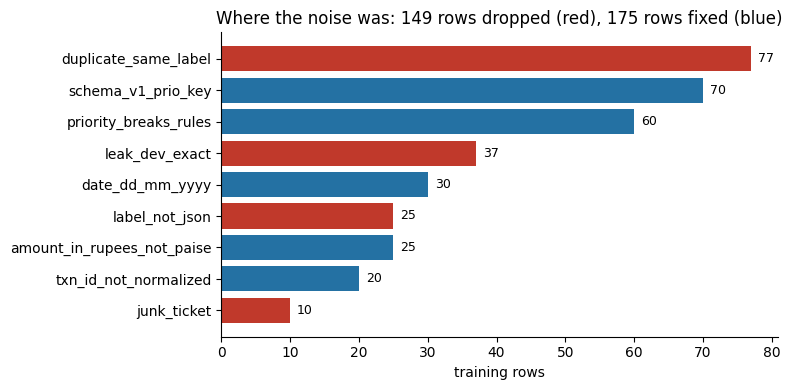

train_clean: 1296 rows -> /content/drive/MyDrive/nimbus_triage/runs/data/train_clean.jsonl
train_raw_noleak: 1408 rows (only dev leaks removed, for the raw-vs-clean experiment)
cleaning_log.csv: 324 rows -> /content/drive/MyDrive/nimbus_triage/cleaning_log.csv


In [9]:
import matplotlib.pyplot as plt

dev_ids_leaked = findings["leak_dev_exact"] | findings["leak_dev_same_body"] | findings["leak_test_exact"] | findings["leak_test_same_body"]
train_clean = [
    {"id": r["id"], "messages": [r["messages"][0], r["messages"][1], {"role": "assistant", "content": canonical(fixed_labels[r["id"]])}]}
    for r in train_raw if r["id"] in fixed_labels
]
train_noleak = [r for r in train_raw if r["id"] not in dev_ids_leaked]

CLEAN_DIR = RUNS / "data"
save_jsonl(train_clean, CLEAN_DIR / "train_clean.jsonl")
save_jsonl(train_noleak, CLEAN_DIR / "train_raw_noleak.jsonl")
log.to_csv(ROOT / "cleaning_log.csv", index=False)


def violations(rows):
    out = Counter()
    for r in rows:
        y = parse_label(label_text(r))
        if y is None or list(y) != KEYS:
            out["structure"] += 1
            continue
        if label_text(r) != canonical(y):
            out["format"] += 1
        if not (y["txn_id"] is None or TXN_ID.fullmatch(y["txn_id"])):
            out["txn_id_format"] += 1
        if not (y["txn_date"] is None or ISO_DATE.fullmatch(y["txn_date"])):
            out["date_format"] += 1
        ref = reference_fields(r, y["category"])
        amount = ref["amount_paise"] if type(ref["amount_paise"]) is int else y["amount_paise"]
        pri = rule_priority(y["category"], amount, clean_body(r))
        for k in ["amount_paise", "txn_date", "txn_id", "channel", "language"]:
            if ref[k] != y[k]:
                out[k] += 1
        out["priority"] += pri != y["priority"]
        out["needs_human"] += rule_needs_human(pri, clean_body(r)) != y["needs_human"]
    return out


before, after = violations(train_noleak), violations(train_clean)
summary = pd.DataFrame({"raw (dev leaks removed)": before, "clean": after}).fillna(0).astype(int)
summary.loc["rows"] = [len(train_noleak), len(train_clean)]
print(summary.to_string())

dev_check = violations(dev)
dev_bad = {k: v for k, v in dev_check.items() if v}
print(f"\nreference labeller vs clean dev labels ({len(dev)} rows), disagreements per field: {dev_bad or 'none'}")

users = [norm_text(user_text(r)) for r in train_clean]
assert len(users) == len(set(users)), "duplicates left"
assert not (set(users) & dev_users), "dev leak left"
assert sum(after.values()) == 0, "clean set still breaks a rule"

counts = Counter(code for reason in log["reason"] for code in reason.split(";"))
codes = [c for c, _ in counts.most_common()][::-1]
colors = ["#c0392b" if any(c == d for d, _ in DROP_ORDER) else "#2471a3" for c in codes]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(codes, [counts[c] for c in codes], color=colors)
for i, c in enumerate(codes):
    ax.text(counts[c] + 1, i, str(counts[c]), va="center", fontsize=9)
ax.set_xlabel("training rows")
ax.set_title(f"Where the noise was: {sum(log.action == 'drop')} rows dropped (red), {sum(log.action == 'fix')} rows fixed (blue)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(RESULTS / "audit_noise.png", dpi=150)
plt.show()

print(f"train_clean: {len(train_clean)} rows -> {CLEAN_DIR / 'train_clean.jsonl'}")
print(f"train_raw_noleak: {len(train_noleak)} rows (only dev leaks removed, for the raw-vs-clean experiment)")
print(f"cleaning_log.csv: {len(log)} rows -> {ROOT / 'cleaning_log.csv'}")

## 2. Chat template and sequence length

At test time the model gets the `system` and `user` messages formatted with Qwen's own chat template, followed by the assistant header. It must then write the JSON and stop. Training uses exactly the same formatting:

`prompt = apply_chat_template([system, user], add_generation_prompt=True)`, then `target = label_json + "<|im_end|>"`

Loss is computed only on `target`. `<|im_end|>` is included so the model learns to stop, because it is the tokenizer's EOS token and `generate` halts on it.

The training sequence length is chosen from the measured token lengths below, not guessed. Long tickets carry quoted email threads, and the test set has them too, so they cannot be cut.

In [10]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)
END = "<|im_end|>"
END_ID = tokenizer.convert_tokens_to_ids(END)
assert tokenizer.eos_token == END


def prompt_messages(row, system=None):
    return [{"role": "system", "content": system or system_text(row)}, {"role": "user", "content": user_text(row)}]


def prompt_string(row, system=None):
    return tokenizer.apply_chat_template(prompt_messages(row, system), tokenize=False, add_generation_prompt=True)


def encode_example(row):
    prompt_ids = tokenizer(prompt_string(row), add_special_tokens=False)["input_ids"]
    target_ids = tokenizer(label_text(row) + END, add_special_tokens=False)["input_ids"]
    return {
        "input_ids": prompt_ids + target_ids,
        "labels": [-100] * len(prompt_ids) + target_ids,
        "prompt_len": len(prompt_ids),
        "target_len": len(target_ids),
    }


example = train_clean[0]
print(prompt_string(example) + label_text(example) + END)

mismatch = 0
for r in train_clean:
    full = tokenizer.apply_chat_template(r["messages"], tokenize=False)
    full_ids = tokenizer(full, add_special_tokens=False)["input_ids"]
    enc = encode_example(r)
    if full_ids[: len(enc["input_ids"])] != enc["input_ids"]:
        mismatch += 1
print(f"\nprompt + target tokenization identical to the full chat template on {len(train_clean) - mismatch}/{len(train_clean)} rows")
assert mismatch == 0

enc = encode_example(example)
trained_on = tokenizer.decode([t for t, l in zip(enc["input_ids"], enc["labels"]) if l != -100])
print("tokens with loss:", repr(trained_on))
assert trained_on == label_text(example) + END

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

<|im_start|>system
You are NimbusPay's ticket triage model. Read the ticket and return the triage JSON.<|im_end|>
<|im_start|>user
Received: 2026-07-25 (Sat)
Source: app-chat

Hi, I have a top up that didn't go through. Why? It was today. Mode: internet banking. My phone is a Redmi Note 12. It is 4.7k in total. My account balance is 258 rupees right now. The txn id is NP1599046332. Waiting for your reply.<|im_end|>
<|im_start|>assistant
{"category": "payment_failed", "priority": "P3", "amount_paise": 470000, "txn_date": "2026-07-25", "txn_id": "NP1599046332", "channel": "netbanking", "language": "en", "needs_human": false}<|im_end|>

prompt + target tokenization identical to the full chat template on 1296/1296 rows
tokens with loss: '{"category": "payment_failed", "priority": "P3", "amount_paise": 470000, "txn_date": "2026-07-25", "txn_id": "NP1599046332", "channel": "netbanking", "language": "en", "needs_human": false}<|im_end|>'


              p50  p90  p95   p99  p100   mean
train prompt  103  135  147  1741  2145  147.9
dev prompt    106  136  142  1464  2115  131.5
test prompt   108  143  151  1827  2089  151.7
train answer   65   79   80    82    84   63.2
dev answer     67   80   81    82    82   64.1

train rows with a quoted email: 36; train sequences over 512 tokens: 36 (2.8%)
test prompts over 512 tokens: 11

longest train sequence 2214 tokens -> MAX_LEN = 2240 (no row is truncated)
longest answer 84 tokens, well inside max_new_tokens=200
longest test prompt 2089 tokens; inference never truncates, so this only needs to fit in memory


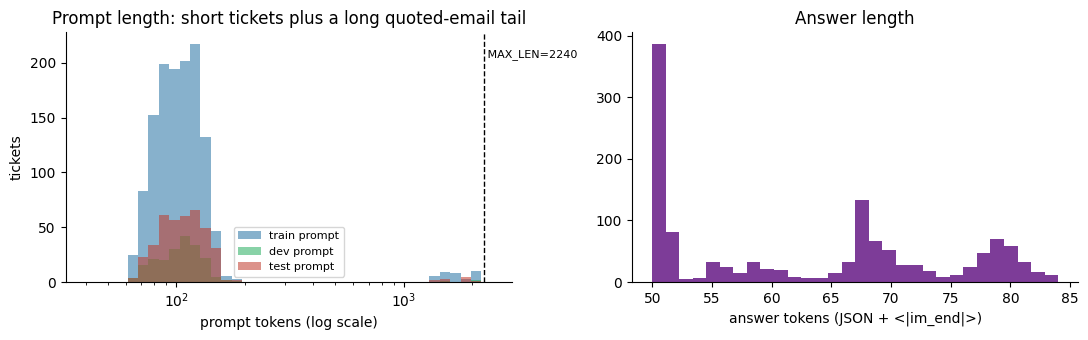

In [11]:
def prompt_len(row):
    return len(tokenizer(prompt_string(row), add_special_tokens=False)["input_ids"])


lengths = {
    "train prompt": [prompt_len(r) for r in train_clean],
    "dev prompt": [prompt_len(r) for r in dev],
    "test prompt": [prompt_len(r) for r in test],
    "train answer": [encode_example(r)["target_len"] for r in train_clean],
    "dev answer": [len(tokenizer(label_text(r) + END, add_special_tokens=False)["input_ids"]) for r in dev],
}
pcts = [50, 90, 95, 99, 100]
table = pd.DataFrame({name: np.percentile(v, pcts).round().astype(int) for name, v in lengths.items()}, index=[f"p{p}" for p in pcts]).T
table["mean"] = [round(float(np.mean(v)), 1) for v in lengths.values()]
print(table.to_string())

train_total = [p + a for p, a in zip(lengths["train prompt"], lengths["train answer"])]
quoted = sum(any(ln.lstrip().startswith(">") for ln in user_text(r).split("\n")) for r in train_clean)
long_rows = sum(t > 512 for t in train_total)
print(f"\ntrain rows with a quoted email: {quoted}; train sequences over 512 tokens: {long_rows} ({long_rows / len(train_total):.1%})")
print(f"test prompts over 512 tokens: {sum(t > 512 for t in lengths['test prompt'])}")

MAX_LEN = int(np.ceil(max(train_total) / 64) * 64)
assert max(lengths["train answer"] + lengths["dev answer"]) < MAX_NEW_TOKENS
print(f"\nlongest train sequence {max(train_total)} tokens -> MAX_LEN = {MAX_LEN} (no row is truncated)")
print(f"longest answer {max(lengths['train answer'] + lengths['dev answer'])} tokens, well inside max_new_tokens={MAX_NEW_TOKENS}")
print(f"longest test prompt {max(lengths['test prompt'])} tokens; inference never truncates, so this only needs to fit in memory")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
bins = np.logspace(np.log10(40), np.log10(max(lengths["test prompt"] + train_total) * 1.1), 40)
for name, color in [("train prompt", "#2471a3"), ("dev prompt", "#27ae60"), ("test prompt", "#c0392b")]:
    axes[0].hist(lengths[name], bins=bins, alpha=0.55, label=name, color=color)
axes[0].set_xscale("log")
axes[0].axvline(MAX_LEN, color="black", ls="--", lw=1)
axes[0].text(MAX_LEN, axes[0].get_ylim()[1] * 0.9, f" MAX_LEN={MAX_LEN}", fontsize=8)
axes[0].set_xlabel("prompt tokens (log scale)")
axes[0].set_ylabel("tickets")
axes[0].legend(fontsize=8)
axes[0].set_title("Prompt length: short tickets plus a long quoted-email tail")
axes[1].hist(lengths["train answer"], bins=30, color="#7d3c98")
axes[1].set_xlabel("answer tokens (JSON + <|im_end|>)")
axes[1].set_title("Answer length")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(RESULTS / "token_lengths.png", dpi=150)
plt.show()

## 3. Part B: baselines

Two reference points on dev, with the untouched base model in fp16:

1. **Fixed prompt**: exactly what the fine-tuned model will see (the one-line system prompt and the ticket).
2. **Rules in the prompt**: the full `SCHEMA.md` appended to the system prompt. This is allowed only here, as a reference for how far prompting alone gets.

Inference follows the evaluation protocol: Qwen's chat template, `model.generate` with greedy decoding (`do_sample=False`) and `max_new_tokens=200`, and the output only stripped of whitespace. Everything else stays at the model's own `generation_config`. That includes Qwen's default `repetition_penalty=1.05`, which still applies under greedy decoding. This is what plain `model.generate` does, so it is what the evaluation will do.

Batches are formed from tickets of similar length and left-padded, to keep generation fast on a T4. Step 7 checks that batched outputs equal one-at-a-time outputs.

In [12]:
import gc
import shutil
from transformers import AutoModelForCausalLM, BitsAndBytesConfig

DTYPE = torch.bfloat16 if torch.cuda.is_available() and torch.cuda.get_device_capability(0)[0] >= 8 else torch.float16
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
GEN_KWARGS = {"do_sample": False, "max_new_tokens": MAX_NEW_TOKENS}


def free_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()


def load_model(model_id=BASE_MODEL, four_bit=False, adapter=None):
    kwargs = {"dtype": DTYPE}
    if four_bit:
        kwargs["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=DTYPE, bnb_4bit_use_double_quant=True)
        kwargs["device_map"] = {"": 0}
    model = AutoModelForCausalLM.from_pretrained(model_id, **kwargs)
    if not four_bit:
        model.to(DEVICE)
    if adapter is not None:
        from peft import PeftModel
        model = PeftModel.from_pretrained(model, str(adapter))
    model.eval()
    return model


def length_batches(encoded, token_budget, max_batch):
    order = sorted(range(len(encoded)), key=lambda i: len(encoded[i]))
    batches, current = [], []
    for i in order:
        longest = max([len(encoded[j]) for j in current] + [len(encoded[i])])
        if current and ((longest + MAX_NEW_TOKENS) * (len(current) + 1) > token_budget or len(current) == max_batch):
            batches.append(current)
            current = []
        current.append(i)
    if current:
        batches.append(current)
    return batches


@torch.no_grad()
def generate_predictions(model, rows, system=None, token_budget=24_000, max_batch=32, extra_gen=None, desc="generate"):
    tokenizer.padding_side = "left"
    prompts = [prompt_string(r, system) for r in rows]
    encoded = [tokenizer(p, add_special_tokens=False)["input_ids"] for p in prompts]
    outputs = [None] * len(rows)
    batches = length_batches(encoded, token_budget, max_batch)
    start = time.time()
    for b, idx in enumerate(batches):
        batch = tokenizer.pad({"input_ids": [encoded[i] for i in idx]}, return_tensors="pt").to(model.device)
        gen = model.generate(**batch, **GEN_KWARGS, **(extra_gen or {}), pad_token_id=tokenizer.pad_token_id)
        new_tokens = gen[:, batch["input_ids"].shape[1]:]
        for i, toks in zip(idx, new_tokens):
            outputs[i] = tokenizer.decode(toks, skip_special_tokens=True).strip()
        print(f"\r{desc}: batch {b + 1}/{len(batches)} ({time.time() - start:.0f}s)", end="")
    print()
    return [{"id": r["id"], "output": o} for r, o in zip(rows, outputs)]


def effective_generation_config(model):
    cfg = model.generation_config.to_dict()
    cfg.update(GEN_KWARGS)
    keep = ["do_sample", "max_new_tokens", "repetition_penalty", "temperature", "top_p", "top_k", "eos_token_id"]
    return {k: cfg.get(k) for k in keep}


SMALL_FILES = ["dev_predictions.jsonl", "dev_scores.json", "stress_predictions.jsonl", "stress_scores.json", "train_log.csv", "train_meta.json"]


def export_run(name):
    for fname in SMALL_FILES:
        src = RUNS / name / fname
        if src.exists():
            (RESULTS / name).mkdir(parents=True, exist_ok=True)
            shutil.copy(src, RESULTS / name / fname)


def run_eval(name, model, rows=None, system=None, change="", extra=None, force=False, **gen):
    rows = rows if rows is not None else dev
    out_dir = RUNS / name
    pred_path = out_dir / "dev_predictions.jsonl"
    if pred_path.exists() and not force:
        preds = load_jsonl(pred_path)
        print(f"{name}: reusing saved predictions from {pred_path}")
    else:
        preds = generate_predictions(model, rows, system=system, desc=name, **gen)
        save_jsonl(preds, pred_path)
    res = evaluate(rows, preds)
    (out_dir / "dev_scores.json").write_text(json.dumps(res, indent=1), encoding="utf-8")
    show_scores(res, prefixes=["category="])
    log_experiment({
        "run": name, "change": change,
        "dev_exact": round(res["all"]["exact_match"], 4),
        "dev_field_acc": round(res["all"]["mean_field_acc"], 4),
        "dev_json_valid": round(res["all"]["json_valid"], 4),
        **(extra or {}),
    })
    export_run(name)
    return preds, res

In [13]:
SCHEMA_TEXT = (PACK / "SCHEMA.md").read_text(encoding="utf-8")
RULES_SYSTEM = FIXED_SYSTEM + "\n\nFollow this labelling spec exactly and output only the JSON object.\n\n" + SCHEMA_TEXT
print(f"rules prompt: {len(tokenizer(RULES_SYSTEM)['input_ids'])} tokens added to every request")

free_memory()
base = load_model()
print("effective generation settings:", effective_generation_config(base))

print("\nBaseline 1: fixed prompt")
b1_preds, b1 = run_eval("B1_base_fixed_prompt", base, change="base model, fixed prompt, no fine-tuning")

print("\nBaseline 2: rules in the prompt")
b2_preds, b2 = run_eval("B2_base_rules_in_prompt", base, system=RULES_SYSTEM, change="base model, SCHEMA.md in system prompt",
                        token_budget=16_000, max_batch=8)

baseline_table = pd.DataFrame({
    "B1 fixed prompt": {"json_valid": b1["all"]["json_valid"], "exact_match": b1["all"]["exact_match"],
                        "mean_field_acc": b1["all"]["mean_field_acc"], **b1["all"]["fields"]},
    "B2 rules in prompt": {"json_valid": b2["all"]["json_valid"], "exact_match": b2["all"]["exact_match"],
                           "mean_field_acc": b2["all"]["mean_field_acc"], **b2["all"]["fields"]},
}).round(3)
print(baseline_table.to_string())

for name, preds in [("B1", b1_preds), ("B2", b2_preds)]:
    print(f"\n{name} sample outputs:")
    for p, g in list(zip(preds, dev))[:3]:
        print(f"  {p['id']} gold: {label_text(g)}")
        print(f"  {' ' * len(p['id'])} pred: {p['output'][:300]!r}")

del base
free_memory()

rules prompt: 1355 tokens added to every request


model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

effective generation settings: {'do_sample': False, 'max_new_tokens': 200, 'repetition_penalty': 1.05, 'temperature': 0.7, 'top_p': 0.8, 'top_k': 20, 'eos_token_id': [151645, 151643]}

Baseline 1: fixed prompt
B1_base_fixed_prompt: reusing saved predictions from /content/drive/MyDrive/nimbus_triage/runs/B1_base_fixed_prompt/dev_predictions.jsonl
group                            n   valid   exact  fields
all                            200    0.5%    0.0%    0.0%
category=account_access         19    0.0%    0.0%    0.0%
category=fraud                  15    0.0%    0.0%    0.0%
category=kyc                    24    4.2%    0.0%    0.0%
category=offers                 18    0.0%    0.0%    0.0%
category=other                  16    0.0%    0.0%    0.0%
category=payment_failed         53    0.0%    0.0%    0.0%
category=refund                 55    0.0%    0.0%    0.0%
per-field accuracy: {'category': 0.0, 'priority': 0.0, 'amount_paise': 0.0, 'txn_date': 0.0, 'txn_id': 0.0, 'channel': 0.

## 4. Part C: fine-tuning pipeline

A short, hand-written training loop rather than a framework trainer, so every choice is visible and easy to defend:

| Choice | Value | Why |
|---|---|---|
| Base | `Qwen2.5-3B-Instruct` in fp16 | the T4 has no native bf16, and the 3B model fits in fp16 with room to spare |
| Adapter | LoRA r=16, alpha=32, dropout 0.05 on all attention and MLP projections | ≈30M trainable params, under the 50M cap (r=32 would exceed it) |
| Loss | cross-entropy on the answer JSON and `<|im_end|>` only | the model learns to answer, not to repeat tickets, and learns to stop |
| Batches | 16 tickets per optimizer step, grouped by length, split into micro-batches of at most 8,192 tokens | short tickets do not pay for the padding of quoted-email tickets, and one long row never runs out of memory |
| Logits | the LM head runs only on answer positions | a 152k-word vocabulary over every prompt token would be the largest tensor in training; this skips it |
| Optimizer | AdamW, LR 2e-4, cosine schedule, 3% warmup, no weight decay, gradient clip 1.0, 3 epochs, seed 42 | standard LoRA settings; Part D tests rank and epochs |
| Precision | fp16 autocast with a gradient scaler; LoRA weights kept in fp32 | a stable fp16 recipe for pre-Ampere GPUs |
| Memory | gradient checkpointing | room for the 2,240-token rows |

Each optimizer step averages the loss over every answer token in its 16 tickets, however they are split into micro-batches, so the update does not depend on the batching. Dev loss is measured after each epoch to monitor fitting, never to train.

After training, the adapter is saved in fp16, under 100 MB, the same way it ships in `adapter/`. It is then **loaded fresh onto a clean base model** and scored on dev with the same protocol as the baselines, as a reviewer would do. Every run writes `train_log.csv`, `train_meta.json`, its adapter, its dev predictions and scores under `runs/<name>/`, and appends one row to `runs/experiments.csv`. A run whose adapter is already on Drive is reused, so a Colab disconnect costs nothing.

In [14]:
import contextlib
import math
import torch.nn.functional as F
import matplotlib.pyplot as plt
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from transformers import get_cosine_schedule_with_warmup

LORA_TARGETS = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
TRAINABLE_CAP = 50_000_000


def collate(examples):
    width = max(len(e["input_ids"]) for e in examples)
    ids = torch.full((len(examples), width), tokenizer.pad_token_id, dtype=torch.long)
    labels = torch.full((len(examples), width), -100, dtype=torch.long)
    mask = torch.zeros((len(examples), width), dtype=torch.long)
    for k, e in enumerate(examples):
        n = len(e["input_ids"])
        ids[k, :n] = torch.tensor(e["input_ids"])
        labels[k, :n] = torch.tensor(e["labels"])
        mask[k, :n] = 1
    return {"input_ids": ids, "attention_mask": mask, "labels": labels}


def plan_steps(lengths, rows_per_step, token_budget, rng):
    order = sorted(range(len(lengths)), key=lambda i: (lengths[i] // 32, rng.random()))
    chunks = [order[i:i + rows_per_step] for i in range(0, len(order), rows_per_step)]
    rng.shuffle(chunks)
    steps = []
    for chunk in chunks:
        micro, current = [], []
        for i in sorted(chunk, key=lambda i: lengths[i]):
            if current and lengths[i] * (len(current) + 1) > token_budget:
                micro.append(current)
                current = []
            current.append(i)
        micro.append(current)
        steps.append(micro)
    return steps


def autocast():
    if torch.cuda.is_available() and DTYPE != torch.float32:
        return torch.autocast("cuda", dtype=DTYPE)
    return contextlib.nullcontext()


def answer_loss(model, batch):
    inner = model.get_base_model()
    hidden = inner.model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"], use_cache=False).last_hidden_state
    targets = batch["labels"][:, 1:]
    keep = targets != -100
    logits = inner.lm_head(hidden[:, :-1][keep]).float()
    return F.cross_entropy(logits, targets[keep], reduction="sum"), int(keep.sum())


@torch.no_grad()
def dev_loss(model, encoded, token_budget):
    model.eval()
    lengths = [len(e["input_ids"]) for e in encoded]
    total, count = 0.0, 0
    for micro in plan_steps(lengths, len(encoded), token_budget, random.Random(0)):
        for mb in micro:
            batch = {k: v.to(model.device) for k, v in collate([encoded[i] for i in mb]).items()}
            with autocast():
                loss_sum, n = answer_loss(model, batch)
            total += loss_sum.item()
            count += n
    model.train()
    return total / count


def train_lora(name, rows, rank=16, epochs=3, lr=2e-4, four_bit=False, rows_per_step=16, token_budget=8192,
               warmup_ratio=0.03, seed=SEED, model_id=None, force=False):
    out_dir = RUNS / name
    adapter_dir = out_dir / "adapter"
    meta_path = out_dir / "train_meta.json"
    if meta_path.exists() and (adapter_dir / "adapter_config.json").exists() and not force:
        print(f"{name}: reusing trained adapter from {adapter_dir}")
        return json.loads(meta_path.read_text(encoding="utf-8"))

    set_seed(seed)
    free_memory()
    model = load_model(model_id or BASE_MODEL, four_bit=four_bit)
    model.config.use_cache = False
    checkpointing = {"use_reentrant": False}
    if four_bit:
        model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True, gradient_checkpointing_kwargs=checkpointing)
    else:
        model.gradient_checkpointing_enable(gradient_checkpointing_kwargs=checkpointing)
    config = LoraConfig(r=rank, lora_alpha=2 * rank, lora_dropout=0.05, target_modules=LORA_TARGETS, bias="none", task_type="CAUSAL_LM")
    model = get_peft_model(model, config)
    params = [p for p in model.parameters() if p.requires_grad]
    trainable = sum(p.numel() for p in params)
    assert trainable <= TRAINABLE_CAP, trainable
    assert all(p.dtype == torch.float32 for p in params)
    print(f"{name}: {len(rows)} rows, {'4-bit NF4' if four_bit else str(DTYPE).split('.')[-1]} base, LoRA r={rank}, trainable params {trainable:,}")

    encoded = [encode_example(r) for r in rows]
    lengths = [len(e["input_ids"]) for e in encoded]
    dev_encoded = [encode_example(r) for r in dev]
    total_steps = math.ceil(len(rows) / rows_per_step) * epochs
    optimizer = torch.optim.AdamW(params, lr=lr, weight_decay=0.0)
    scheduler = get_cosine_schedule_with_warmup(optimizer, math.ceil(warmup_ratio * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available() and DTYPE == torch.float16)
    rng = random.Random(seed)
    history, step = [], 0
    start = time.time()
    model.train()
    for epoch in range(1, epochs + 1):
        for micro in plan_steps(lengths, rows_per_step, token_budget, rng):
            n_target = sum(encoded[i]["target_len"] for mb in micro for i in mb)
            step_loss = 0.0
            for mb in micro:
                batch = {k: v.to(model.device) for k, v in collate([encoded[i] for i in mb]).items()}
                with autocast():
                    loss_sum, _ = answer_loss(model, batch)
                scaler.scale(loss_sum / n_target).backward()
                step_loss += loss_sum.item()
            scaler.unscale_(optimizer)
            grad_norm = torch.nn.utils.clip_grad_norm_(params, 1.0).item()
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()
            step += 1
            history.append({"step": step, "epoch": epoch, "loss": step_loss / n_target,
                            "lr": scheduler.get_last_lr()[0], "grad_norm": grad_norm, "dev_loss": None})
            print(f"\r{name}: epoch {epoch}/{epochs} step {step}/{total_steps} loss {step_loss / n_target:.4f} "
                  f"({(time.time() - start) / 60:.1f} min)", end="")
        history[-1]["dev_loss"] = dev_loss(model, dev_encoded, token_budget)
        print(f"\n{name}: epoch {epoch} done, dev loss {history[-1]['dev_loss']:.4f}")

    minutes = (time.time() - start) / 60
    peak = torch.cuda.max_memory_allocated() / 1e9 if torch.cuda.is_available() else 0.0
    for p in params:
        p.data = p.data.to(torch.float16)
    model.save_pretrained(adapter_dir)
    size_mb = sum(f.stat().st_size for f in adapter_dir.iterdir()) / 1e6
    meta = {"run": name, "train_rows": len(rows), "trainable_params": trainable, "peak_gpu_gb": round(peak, 2),
            "train_minutes": round(minutes, 1), "rank": rank, "epochs": epochs, "lr": lr, "four_bit": four_bit,
            "rows_per_step": rows_per_step, "steps": total_steps, "adapter_mb": round(size_mb, 1)}
    pd.DataFrame(history).to_csv(out_dir / "train_log.csv", index=False)
    meta_path.write_text(json.dumps(meta, indent=1), encoding="utf-8")
    print(f"{name}: trained in {minutes:.1f} min, peak GPU {peak:.1f} GB, adapter {size_mb:.0f} MB")
    del model, optimizer, scheduler, scaler, params
    free_memory()
    return meta


def stress_eval(name, model, stress, force=False):
    path = RUNS / name / "stress_predictions.jsonl"
    if path.exists() and not force:
        preds = load_jsonl(path)
    else:
        preds = generate_predictions(model, stress, desc=f"{name} stress")
        save_jsonl(preds, path)
    res = evaluate(stress, preds)
    (RUNS / name / "stress_scores.json").write_text(json.dumps(res, indent=1), encoding="utf-8")
    print(f"{name} on the dev stress set: exact {res['all']['exact_match']:.1%}, fields {res['all']['mean_field_acc']:.1%}")
    return {"stress_exact": round(res["all"]["exact_match"], 4), "stress_field_acc": round(res["all"]["mean_field_acc"], 4)}


def train_and_eval(name, rows, change, four_bit=False, model_id=None, force=False, stress=None, **train_kwargs):
    meta = train_lora(name, rows, four_bit=four_bit, model_id=model_id, force=force, **train_kwargs)
    model = load_model(model_id or BASE_MODEL, four_bit=four_bit, adapter=RUNS / name / "adapter")
    extra = {k: meta[k] for k in ["train_rows", "peak_gpu_gb", "train_minutes", "trainable_params"]}
    if stress is not None:
        extra.update(stress_eval(name, model, stress, force=force))
    preds, res = run_eval(name, model, change=change, extra=extra, force=force)
    del model
    free_memory()
    return meta, preds, res


def plot_training(names, path):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    for name in names:
        log = pd.read_csv(RESULTS / name / "train_log.csv")
        axes[0].plot(log["step"], log["loss"].rolling(5, min_periods=1).mean(), label=name)
        ends = log.dropna(subset=["dev_loss"])
        axes[1].plot(ends["epoch"], ends["dev_loss"], marker="o", label=name)
    axes[0].set_yscale("log")
    axes[0].set_xlabel("optimizer step")
    axes[0].set_ylabel("train loss (5-step mean)")
    axes[0].set_title("Training loss on answer tokens")
    axes[1].set_xlabel("epoch")
    axes[1].set_ylabel("dev loss")
    axes[1].set_title("Dev loss after each epoch")
    for ax in axes:
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()


def experiments_table():
    return pd.read_csv(EXPERIMENTS_CSV).drop(columns=["timestamp"]).set_index("run")

optimizer steps per epoch: 81, forward passes per epoch: 89, largest micro-batch: 16 rows
padding efficiency: 93.6% with length grouping vs 24.6% with random batches
LM head runs on 29.9% of token positions (answer tokens only)
E2_clean_lora_r16: reusing trained adapter from /content/drive/MyDrive/nimbus_triage/runs/E2_clean_lora_r16/adapter


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

E2_clean_lora_r16: reusing saved predictions from /content/drive/MyDrive/nimbus_triage/runs/E2_clean_lora_r16/dev_predictions.jsonl
group                            n   valid   exact  fields
all                            200  100.0%   92.0%   98.3%
category=account_access         19  100.0%  100.0%  100.0%
category=fraud                  15  100.0%   86.7%   97.5%
category=kyc                    24  100.0%  100.0%  100.0%
category=offers                 18  100.0%  100.0%  100.0%
category=other                  16  100.0%  100.0%  100.0%
category=payment_failed         53  100.0%   88.7%   97.6%
category=refund                 55  100.0%   85.5%   96.8%
per-field accuracy: {'category': 0.99, 'priority': 0.945, 'amount_paise': 0.995, 'txn_date': 0.98, 'txn_id': 1.0, 'channel': 1.0, 'language': 1.0, 'needs_human': 0.955}


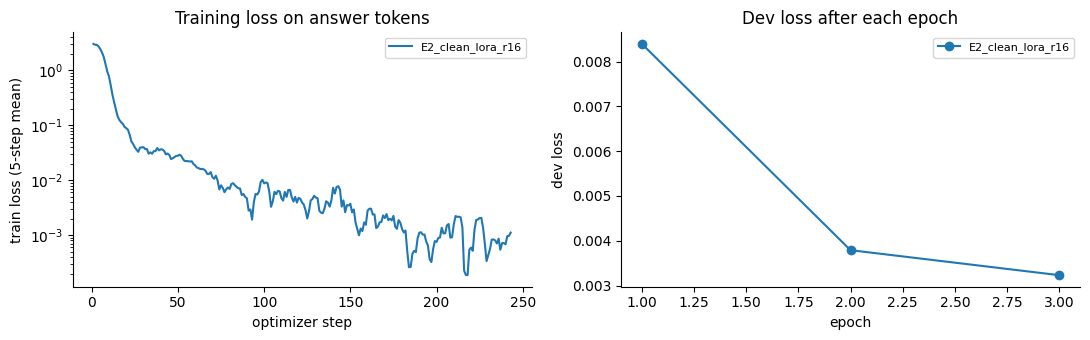

                                                                                 change  train_rows  dev_exact  dev_field_acc  dev_json_valid  stress_exact  stress_field_acc  peak_gpu_gb  train_minutes  trainable_params
run                                                                                                                                                                                                                        
E1_raw_lora_r16          raw train (leaks and unparsable labels removed, nothing fixed)      1383.0      0.915         0.9856           1.000        0.7371            0.9493        10.40           25.3        29933568.0
E3_clean_qlora_r16                                cleaned train, 4-bit NF4 base (QLoRA)      1296.0      0.945         0.9888           1.000        0.7886            0.9543         8.06           28.7        29933568.0
E4_clean_lora_r16_2ep                              cleaned train, 2 epochs instead of 3      1296.0      0.865         0

In [15]:
train_lengths = [len(encode_example(r)["input_ids"]) for r in train_clean]
train_targets = [encode_example(r)["target_len"] for r in train_clean]
plan = plan_steps(train_lengths, 16, 8192, random.Random(SEED))
padded = sum(len(mb) * max(train_lengths[i] for i in mb) for micro in plan for mb in micro)
shuffled = list(range(len(train_clean)))
random.Random(SEED).shuffle(shuffled)
naive = sum(16 * max(train_lengths[i] for i in shuffled[k:k + 16]) for k in range(0, len(shuffled), 16))
print(f"optimizer steps per epoch: {len(plan)}, forward passes per epoch: {sum(len(m) for m in plan)}, "
      f"largest micro-batch: {max(len(mb) for m in plan for mb in m)} rows")
print(f"padding efficiency: {sum(train_lengths) / padded:.1%} with length grouping vs {sum(train_lengths) / naive:.1%} with random batches")
print(f"LM head runs on {sum(train_targets) / sum(train_lengths):.1%} of token positions (answer tokens only)")

REFERENCE = {"rank": 16, "epochs": 3, "lr": 2e-4, "rows_per_step": 16}
e2_meta, e2_preds, e2 = train_and_eval("E2_clean_lora_r16", train_clean, change="cleaned train, fp16 base, LoRA r16 (reference)", **REFERENCE)
plot_training(["E2_clean_lora_r16"], RESULTS / "training_curves_reference.png")
print(experiments_table().to_string())

## 5. Part D: controlled experiments

Every run starts from the **E2 reference** (cleaned train, fp16 base, LoRA r16, 3 epochs, LR 2e-4, seed 42) and changes exactly one thing:

| Run | One change | Question it answers |
|---|---|---|
| E1 | raw train: only dev/test leaks and unparsable labels removed, no fixes, no deduplication | What does the label noise found in the audit cost? |
| E2 | none (reference) | |
| E3 | base loaded in 4-bit NF4 (QLoRA) | How much accuracy do we trade for memory? |
| E4 | 2 epochs instead of 3 | Is the third epoch worth its 8 minutes? |
| E5 | + 620 synthetic rows from rule-based augmentation | Does teaching the rules on harder surface forms help? |

**E5, rule-based augmentation (my own idea).** The test set is described as harder. Instead of guessing at its contents, I rewrite **train** tickets in the ways the spec says make a ticket hard, and compute the new label from the rules:

- **txn_id_format**: `NP1234567890` becomes `np 12345 67890`, `N P 1234 567 890`, `Np-123-456-7890`.
- **amount_threshold**: the amount is replaced by one at or around the ₹5,000 and ₹50,000 priority cut-offs, written as `Rs.4999/-`, `₹49,999`, `49.5k` or `1.5 lakh`. Priority and needs_human are recomputed.
- **relative_date**: the date becomes `yesterday`, `parso` or `6 din pehle`, and `txn_date` is recomputed from Received.
- **distractor**: a balance, limit, fee or bank reference sentence that must be ignored.
- **quoted_email**: a quoted earlier email with an old date and amount that must be ignored.
- **legal_threat**: a sentence mentioning RBI, a lawyer or consumer court, so the ticket becomes P1 and needs a human.
- **repeat_contact**: a sentence such as "third time" or "baar baar", so the ticket needs a human.

Two safeguards keep this from adding new label noise:
- Only train tickets where the audit's reference labeller agrees with the cleaned label on **all eight fields** are rewritten.
- Every rewritten ticket is labelled again independently by the reference labeller. It is kept only if that label matches the label the transformation produced.

The labeller is used only to build training data and is never part of inference.

**Dev stress set.** The same seven transformations applied to dev tickets give a second benchmark of 175 rows. It is used only for evaluation and never for training or tuning. It shows how each model holds up on the kinds of variation the test set is said to contain, and it is scored per transformation through the scorer's `slice` field.

A sixth run, **E6**, comes out of the error analysis and is in section 6.

**Running cost.** E1–E5 together take about 2.5 hours on a T4. With `RUN_ALL_EXPERIMENTS = False` the notebook shows the logged results from `results/` instead of retraining, so a fresh top-to-bottom run stays under the 3-hour limit. All runs are saved, so a Colab disconnect only costs the run in progress.

In [16]:
from datetime import timedelta

DATE_SPAN = re.compile(
    r"\b\d{1,2}[/\-]\d{1,2}[/\-]\d{2,4}\b"
    r"|\b\d{1,2}(?:st|nd|rd|th)?\s+" + MON + r"\b(?:\s+\d{4})?"
    r"|\b" + MON + r"\s+\d{1,2}(?:st|nd|rd|th)?\b(?:,?\s+\d{4})?"
    r"|\b\d+\s*(?:days? ago|din pehle)"
    r"|day before yesterday|\bparso\b|\byesterday\b|\bkal\b|\btoday\b|\baaj\b",
    re.I,
)
SENTENCE_END = re.compile(r"(?<=[.!?])\s+(?=\S)")
THRESHOLD_RUPEES = [4900, 4999, 5000, 5001, 5100, 49500, 49999, 50000, 50001, 51000, 125000, 150000, 800, 2500, 20000]
PHRASES = {
    "legal": {
        "en": ["If this is not resolved I will escalate to the RBI ombudsman.", "I am sending a legal notice.",
               "My lawyer will contact you about this.", "I will take this to consumer court."],
        "hi-en": ["Warna main consumer court jaunga.", "RBI ko complaint kar dunga.", "Mera vakil legal notice bhejega."],
    },
    "repeat": {
        "en": ["This is the third time I am writing about this.", "I have contacted support about this before.",
               "This is my second complaint on the same issue."],
        "hi-en": ["Main baar baar complaint kar raha hoon.", "Teesri baar likh raha hoon.", "Pehle bhi complaint ki thi."],
    },
}


def indian(n):
    s = str(n)
    head, tail = s[:-3], s[-3:]
    groups = []
    while len(head) > 2:
        groups.insert(0, head[-2:])
        head = head[:-2]
    return ",".join(([head] if head else []) + groups + [tail])


def render_amount(rupees, rng):
    styles = [f"Rs {rupees}", f"Rs.{rupees}/-", f"₹{indian(rupees)}", f"INR {indian(rupees)}", f"{rupees} rupees"]
    if rupees % 100 == 0 and rupees < 100_000:
        styles.append(f"{rupees / 1000:g}k")
    if rupees % 1000 == 0 and rupees >= 100_000:
        styles.append(f"{rupees / 100_000:g} lakh")
    return rng.choice(styles)


def split_ticket(row):
    return user_text(row).split("\n\n", 1)


def make_row(row, body, label, kind):
    head = split_ticket(row)[0]
    return {"id": f"{row['id']}-{kind}", "slice": kind,
            "messages": [row["messages"][0], {"role": "user", "content": head + "\n\n" + body},
                         {"role": "assistant", "content": canonical(label)}]}


def rule_label(row, category):
    text = clean_body(row)
    ref = reference_fields(row, category)
    priority = rule_priority(category, ref["amount_paise"], text)
    return {"category": category, "priority": priority, "amount_paise": ref["amount_paise"], "txn_date": ref["txn_date"],
            "txn_id": ref["txn_id"], "channel": ref["channel"], "language": ref["language"],
            "needs_human": rule_needs_human(priority, text)}


def insert_sentence(body, sentence, rng):
    cuts = [m.start() for m in SENTENCE_END.finditer(body)]
    if not cuts:
        return None
    at = rng.choice(cuts[: max(1, len(cuts) - 1)])
    return body[:at] + " " + sentence + body[at:]


def relabel(label, row, body):
    text = clean_body(make_row(row, body, label, "draft"))
    priority = rule_priority(label["category"], label["amount_paise"], text)
    return {**label, "priority": priority, "needs_human": rule_needs_human(priority, text)}


def aug_txn_id(row, body, label, rng):
    matches = list(TXN_ID_LOOSE.finditer(body))
    if not label["txn_id"] or len(matches) != 1:
        return None
    m = matches[0]
    end = m.end() - (len(m.group(1)) - len(m.group(1).rstrip(" \t\r\n-")))
    d = label["txn_id"][2:]
    new = rng.choice([f"np {d[:5]} {d[5:]}", f"NP-{d}", f"N P {d[:4]} {d[4:7]} {d[7:]}", f"np{d}", f"NP#{d}", f"Np-{d[:3]}-{d[3:6]}-{d[6:]}"])
    return body[:m.start()] + new + body[end:], label


def aug_amount(row, body, label, rng):
    if label["amount_paise"] is None:
        return None
    masked = NOT_MONEY.sub(lambda m: " " * len(m.group(0)), body)
    spans = [m.span() for m in MONEY.finditer(masked)
             if to_paise(m.group("a") or m.group("b") or m.group("c"), m.group("am") or m.group("bm")) == label["amount_paise"]]
    if not spans:
        spans = [m.span("d") if m.group("d") else m.span("e") for m in BARE_AMOUNT.finditer(masked)
                 if to_paise(m.group("d") or m.group("e"), None) == label["amount_paise"]]
    if len(spans) != 1:
        return None
    start, end = spans[0]
    end = start + len(body[start:end].rstrip())
    rupees = rng.choice(THRESHOLD_RUPEES)
    new_body = body[:start] + render_amount(rupees, rng) + body[end:]
    return new_body, relabel({**label, "amount_paise": rupees * 100}, row, new_body)


def aug_relative_date(row, body, label, rng):
    matches = list(DATE_SPAN.finditer(body))
    if not label["txn_date"] or len(matches) != 1:
        return None
    m = matches[0]
    days = rng.choice([1, 2, 3, 4, 5, 6, 7, 10])
    if label["language"] == "hi-en":
        phrase = {1: "kal", 2: "parso"}.get(days, f"{days} din pehle")
    else:
        phrase = {1: "yesterday", 2: "the day before yesterday"}.get(days, f"{days} days ago")
    start = m.start() - 3 if body[max(0, m.start() - 3):m.start()].lower() == "on " else m.start()
    new_date = (received_date(row) - timedelta(days=days)).isoformat()
    return body[:start] + phrase + body[m.end():], {**label, "txn_date": new_date}


def aug_distractor(row, body, label, rng):
    rupees = rng.choice([258, 1200, 7450, 18000, 64000, 120000])
    if label["language"] == "hi-en":
        options = [f"Account mein abhi {indian(rupees)} rupees pade hain.", f"Mera daily limit {rng.choice([10, 25, 50])}k hai."]
    else:
        options = [f"FYI my account balance is ₹{indian(rupees)} right now.", f"My daily limit is {rng.choice([10, 25, 50])}k.",
                   f"Bank ref {rng.randint(10 ** 9, 10 ** 11)}.", f"There was a fee of Rs {rng.choice([10, 25, 49])} as well."]
    new_body = insert_sentence(body, rng.choice(options), rng)
    return (new_body, label) if new_body else None


def aug_quoted_email(row, body, label, rng):
    if ticket_source(row) != "email":
        return None
    old = received_date(row) - timedelta(days=rng.randint(20, 60))
    quote = (f"\n\n> On {old.day} {old.strftime('%b %Y')}, NimbusPay Support wrote:\n"
             f"> We have registered your earlier request about a payment of Rs {rng.randint(500, 90000)} "
             f"dated {old.strftime('%d/%m/%Y')} under ticket #{rng.randint(10000, 99999)}.")
    return body.rstrip() + quote, label


def aug_phrase(kind):
    def apply(row, body, label, rng):
        new_body = insert_sentence(body, rng.choice(PHRASES[kind][label["language"]]), rng)
        if new_body is None:
            return None
        new_label = relabel(label, row, new_body)
        return (new_body, new_label) if new_label != label else None
    return apply


AUGMENTERS = {
    "txn_id_format": aug_txn_id,
    "amount_threshold": aug_amount,
    "relative_date": aug_relative_date,
    "distractor": aug_distractor,
    "quoted_email": aug_quoted_email,
    "legal_threat": aug_phrase("legal"),
    "repeat_contact": aug_phrase("repeat"),
}
TRAIN_QUOTA = {"txn_id_format": 90, "amount_threshold": 150, "relative_date": 100, "distractor": 100,
               "quoted_email": 50, "legal_threat": 70, "repeat_contact": 60}
STRESS_QUOTA = {kind: 25 for kind in AUGMENTERS}


def augment(rows, quota, seed):
    rng = random.Random(seed)
    trusted = []
    for r in rows:
        y = json.loads(label_text(r))
        if not any(ln.lstrip().startswith(">") for ln in user_text(r).split("\n")) and rule_label(r, y["category"]) == y:
            trusted.append((r, y))
    out, stats = [], {}
    for kind, n in quota.items():
        made = rejected = 0
        for r, y in rng.sample(trusted, len(trusted)):
            if made == n:
                break
            result = AUGMENTERS[kind](r, split_ticket(r)[1], y, rng)
            if result is None:
                continue
            new = make_row(r, result[0], result[1], kind)
            if rule_label(new, y["category"]) != result[1] or (label_text(new) == label_text(r) and user_text(new) == user_text(r)):
                rejected += 1
                continue
            out.append(new)
            made += 1
        stats[kind] = {"made": made, "rejected by the checker": rejected}
    return out, len(trusted), pd.DataFrame(stats).T


train_aug_extra, trusted_train, aug_stats = augment(train_clean, TRAIN_QUOTA, SEED)
train_aug = train_clean + train_aug_extra
save_jsonl(train_aug, RUNS / "data" / "train_aug.jsonl")
print(f"train rows the rule checker fully agrees with: {trusted_train}/{len(train_clean)}")
print(aug_stats.to_string())
print(f"E5 training set: {len(train_clean)} cleaned + {len(train_aug_extra)} synthetic = {len(train_aug)} rows")

dev_stress, trusted_dev, stress_stats = augment(dev, STRESS_QUOTA, SEED + 1)
print(f"\ndev stress set (evaluation only, never trained on): {len(dev_stress)} rows from {trusted_dev} dev tickets")
print(stress_stats.to_string())

shown = set()
for r in train_aug_extra:
    if r["slice"] in shown:
        continue
    shown.add(r["slice"])
    src = next(x for x in train_clean if x["id"] == r["id"].rsplit("-", 1)[0])
    print(f"\n[{r['slice']}] {src['id']}")
    print("  before:", ticket_body(src).replace("\n", " ")[:260])
    print("  after: ", ticket_body(r).replace("\n", " ")[:260])
    print("  label: ", label_text(r))

train rows the rule checker fully agrees with: 1260/1296
                  made  rejected by the checker
txn_id_format       90                        7
amount_threshold   150                        0
relative_date      100                        2
distractor         100                        0
quoted_email        50                        0
legal_threat        70                        1
repeat_contact      60                        0
E5 training set: 1296 cleaned + 620 synthetic = 1916 rows

dev stress set (evaluation only, never trained on): 175 rows from 197 dev tickets
                  made  rejected by the checker
txn_id_format       25                        5
amount_threshold    25                        0
relative_date       25                        1
distractor          25                        0
quoted_email        25                        0
legal_threat        25                        0
repeat_contact      25                        0

[txn_id_format] tr-00054
  before

RUN_ALL_EXPERIMENTS is False: showing the results logged in results/ (set it to True to retrain E1, E3, E4, E5: about 2.5 h on a T4)
                                                                                 change  train_rows  dev_exact  dev_field_acc  stress_exact  stress_field_acc  peak_gpu_gb  train_minutes  trainable_params
run                                                                                                                                                                                                        
E1_raw_lora_r16          raw train (leaks and unparsable labels removed, nothing fixed)      1383.0      0.915         0.9856        0.7371            0.9493        10.40           25.3        29933568.0
E3_clean_qlora_r16                                cleaned train, 4-bit NF4 base (QLoRA)      1296.0      0.945         0.9888        0.7886            0.9543         8.06           28.7        29933568.0
E4_clean_lora_r16_2ep                              

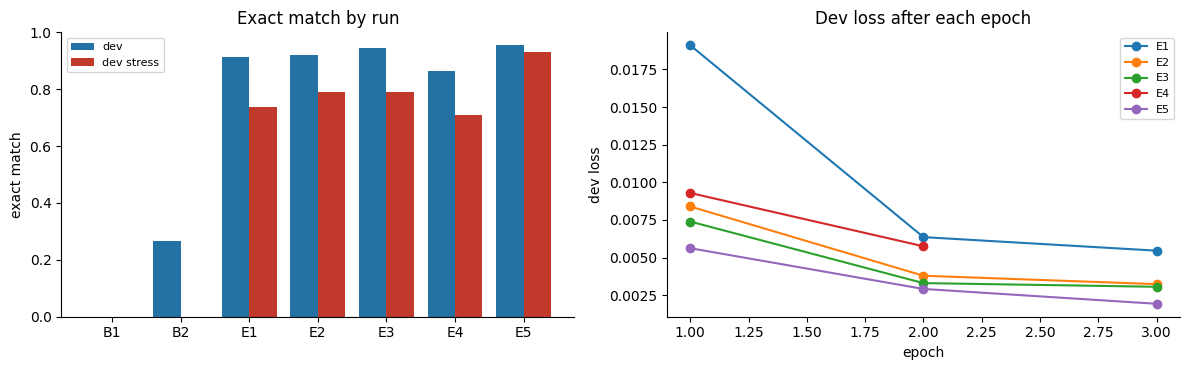

In [17]:
RUN_ALL_EXPERIMENTS = False

train_e1 = [r for r in train_noleak if r["id"] not in findings["label_not_json"]]
EXPERIMENTS = [
    ("E1_raw_lora_r16", train_e1, "raw train (leaks and unparsable labels removed, nothing fixed)", {}),
    ("E2_clean_lora_r16", train_clean, "cleaned train, fp16 base, LoRA r16 (reference)", {}),
    ("E3_clean_qlora_r16", train_clean, "cleaned train, 4-bit NF4 base (QLoRA)", {"four_bit": True}),
    ("E4_clean_lora_r16_2ep", train_clean, "cleaned train, 2 epochs instead of 3", {"epochs": 2}),
    ("E5_aug_lora_r16", train_aug, f"cleaned train + {len(train_aug_extra)} rule-checked synthetic rows", {}),
]

if RUN_ALL_EXPERIMENTS:
    for name, rows, change, overrides in EXPERIMENTS:
        print(f"\n===== {name}: {change} ({len(rows)} rows)")
        train_and_eval(name, rows, change, stress=dev_stress, **{**REFERENCE, **overrides})
else:
    print("RUN_ALL_EXPERIMENTS is False: showing the results logged in results/ (set it to True to retrain E1, E3, E4, E5: about 2.5 h on a T4)")

names = [n for n, *_ in EXPERIMENTS]
table = experiments_table()
summary = table[["change", "train_rows", "dev_exact", "dev_field_acc", "stress_exact", "stress_field_acc",
                 "peak_gpu_gb", "train_minutes", "trainable_params"]]
print(summary.to_string())


def load_scores(name, kind):
    path = RESULTS / name / f"{kind}_scores.json"
    return json.loads(path.read_text(encoding="utf-8")) if path.exists() else None


fields = pd.DataFrame({n: load_scores(n, "dev")["all"]["fields"] for n in ["B2_base_rules_in_prompt"] + names}).round(3)
print("\nper-field dev accuracy:")
print(fields.to_string())

slices = pd.DataFrame({n: {k.split("=", 1)[1]: v["exact_match"] for k, v in load_scores(n, "stress").items() if k.startswith("slice=")}
                       for n in names}).round(3)
print("\ndev stress set, exact match per transformation:")
print(slices.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
order = ["B1_base_fixed_prompt", "B2_base_rules_in_prompt"] + names
x = np.arange(len(order))
axes[0].bar(x - 0.2, [table.loc[n, "dev_exact"] for n in order], 0.4, label="dev", color="#2471a3")
axes[0].bar(x + 0.2, [table.loc[n, "stress_exact"] if n in names else 0 for n in order], 0.4, label="dev stress", color="#c0392b")
axes[0].set_xticks(x, [n.split("_")[0] for n in order])
axes[0].set_ylabel("exact match")
axes[0].set_ylim(0, 1)
axes[0].set_title("Exact match by run")
axes[0].legend(fontsize=8)
for name in names:
    log = pd.read_csv(RESULTS / name / "train_log.csv").dropna(subset=["dev_loss"])
    axes[1].plot(log["epoch"], log["dev_loss"], marker="o", label=name.split("_")[0])
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("dev loss")
axes[1].set_title("Dev loss after each epoch")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(RESULTS / "experiments.png", dpi=150)
plt.show()

## 6. Part E: error analysis

All of the analysis below is on the best run, **E5** (cleaned train plus rule-checked augmentation). It looks at dev, the 200 real tickets, and at the dev stress set. It works from the saved predictions in `results/`, so it needs no GPU.

1. **Where the errors are**: per-field accuracy, slices by category, language, source and ticket length, and confusion matrices for category and priority.
2. **Are the differences real?** Dev has only 200 rows, so one ticket is worth 0.5 points. Each run is compared with E2 on the *same* tickets, with a paired bootstrap confidence interval and an exact McNemar test.
3. **Every failure, with its cause.** Each wrong prediction on dev and on the stress set is listed with the ticket, the wrong fields and a root-cause tag. The tag is assigned by a small set of rules from the spec, not by hand, so it is reproducible.


E5_aug_lora_r16 dev exact match by category:
                 n  exact  wrong
category                        
account_access  19  1.000      0
fraud           15  0.867      2
kyc             24  0.958      1
offers          18  1.000      0
other           16  1.000      0
payment_failed  53  0.943      3
refund          55  0.945      3

E5_aug_lora_r16 dev exact match by language:
            n  exact  wrong
language                   
en        151  0.954      7
hi-en      49  0.959      2

E5_aug_lora_r16 dev exact match by source:
                 n  exact  wrong
source                          
app-chat        86  0.953      4
email           44  0.955      2
ivr-transcript  30  0.967      1
twitter         40  0.950      2

E5_aug_lora_r16 dev exact match by length:
                                    n  exact  wrong
length                                             
long (>512 tokens, quoted email)    3  1.000      0
short                             197  0.954      9

cate

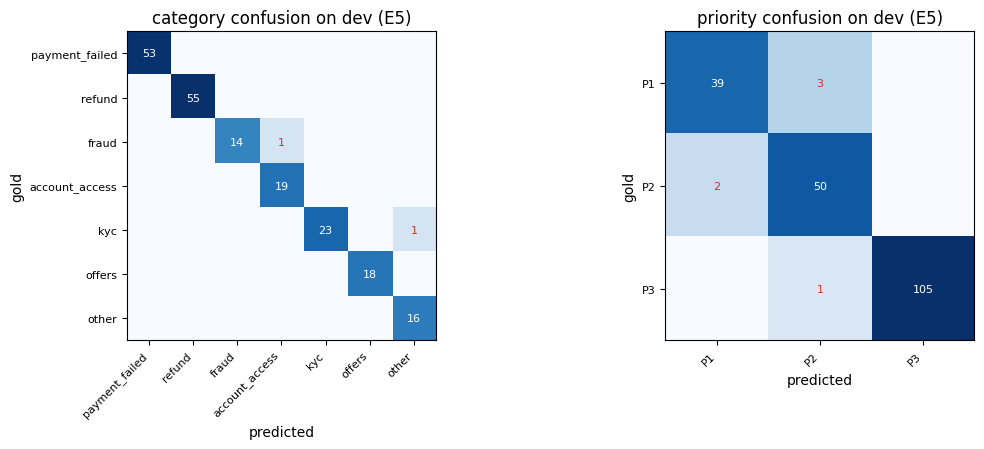

In [18]:
BEST_RUN = "E5_aug_lora_r16"


def parsed_predictions(run, kind="dev"):
    preds = {p["id"]: p["output"] for p in load_jsonl(RESULTS / run / f"{kind}_predictions.jsonl")}
    out = {}
    for rid, text in preds.items():
        try:
            y = json.loads(text)
            out[rid] = y if isinstance(y, dict) else None
        except json.JSONDecodeError:
            out[rid] = None
    return out


def is_exact(gold, pred):
    return pred is not None and set(pred) == set(KEYS) and all(type(pred[k]) is type(gold[k]) and pred[k] == gold[k] for k in KEYS)


dev_gold = {r["id"]: json.loads(label_text(r)) for r in dev}
best = parsed_predictions(BEST_RUN)
dev_frame = pd.DataFrame([{
    "id": r["id"],
    "category": dev_gold[r["id"]]["category"],
    "language": dev_gold[r["id"]]["language"],
    "source": ticket_source(r),
    "length": "long (>512 tokens, quoted email)" if prompt_len(r) > 512 else "short",
    "exact": is_exact(dev_gold[r["id"]], best[r["id"]]),
} for r in dev])

for col in ["category", "language", "source", "length"]:
    t = dev_frame.groupby(col)["exact"].agg(n="size", exact="mean").round(3)
    t["wrong"] = (dev_frame.groupby(col)["exact"].size() - dev_frame.groupby(col)["exact"].sum()).astype(int)
    print(f"\n{BEST_RUN} dev exact match by {col}:")
    print(t.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, key, values in [(axes[0], "category", CATEGORIES), (axes[1], "priority", PRIORITIES)]:
    matrix = pd.crosstab(pd.Categorical([dev_gold[i][key] for i in best], values),
                         pd.Categorical([(best[i] or {}).get(key) for i in best], values), dropna=False)
    ax.imshow(np.log1p(matrix.values), cmap="Blues")
    for (a, b), v in np.ndenumerate(matrix.values):
        if v:
            ax.text(b, a, v, ha="center", va="center", fontsize=8, color="white" if a == b else "#c0392b")
    ax.set_xticks(range(len(values)), values, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(values)), values, fontsize=8)
    ax.set_xlabel("predicted")
    ax.set_ylabel("gold")
    ax.set_title(f"{key} confusion on dev ({BEST_RUN.split('_')[0]})")
    print(f"\n{key} confusion (rows gold, columns predicted):")
    print(matrix.to_string())
plt.tight_layout()
plt.savefig(RESULTS / "confusion.png", dpi=150)
plt.show()

In [19]:
from math import comb


def exact_vector(run, gold, kind="dev"):
    preds = parsed_predictions(run, kind)
    return np.array([is_exact(gold[i], preds.get(i)) for i in gold])


def mcnemar_p(only_a, only_b):
    n, k = only_a + only_b, min(only_a, only_b)
    return 1.0 if n == 0 else min(1.0, 2 * sum(comb(n, i) for i in range(k + 1)) / 2 ** n)


def paired_comparison(run, reference, gold, kind, resamples=10_000):
    a, b = exact_vector(run, gold, kind), exact_vector(reference, gold, kind)
    rng = np.random.default_rng(SEED)
    idx = rng.integers(0, len(a), size=(resamples, len(a)))
    diffs = a[idx].mean(1) - b[idx].mean(1)
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    ref = reference.split("_")[0]
    return {"run": run, "set": kind, "exact": a.mean(), f"vs {ref}": a.mean() - b.mean(),
            "95% CI": f"[{lo:+.3f}, {hi:+.3f}]", "only this right": int((a & ~b).sum()),
            f"only {ref} right": int((~a & b).sum()), "McNemar p": round(mcnemar_p(int((a & ~b).sum()), int((~a & b).sum())), 4)}


stress_gold = {r["id"]: json.loads(label_text(r)) for r in dev_stress}
comparisons = pd.DataFrame([paired_comparison(run, "E2_clean_lora_r16", gold, kind)
                            for kind, gold in [("dev", dev_gold), ("stress", stress_gold)]
                            for run in ["E1_raw_lora_r16", "E3_clean_qlora_r16", "E4_clean_lora_r16_2ep", "E5_aug_lora_r16"]])
print("each run vs the E2 reference on the same tickets (paired bootstrap, 10,000 resamples; exact McNemar test):")
print(comparisons.round(3).to_string(index=False))

each run vs the E2 reference on the same tickets (paired bootstrap, 10,000 resamples; exact McNemar test):
                  run    set  exact  vs E2           95% CI  only this right  only E2 right  McNemar p
      E1_raw_lora_r16    dev  0.915 -0.005 [-0.035, +0.025]                4              5      1.000
   E3_clean_qlora_r16    dev  0.945  0.025 [-0.005, +0.055]                7              2      0.180
E4_clean_lora_r16_2ep    dev  0.865 -0.055 [-0.095, -0.020]                2             13      0.007
      E5_aug_lora_r16    dev  0.955  0.035 [+0.010, +0.065]                8              1      0.039
      E1_raw_lora_r16 stress  0.737 -0.051 [-0.103, +0.000]                7             16      0.093
   E3_clean_qlora_r16 stress  0.789  0.000 [-0.046, +0.046]                9              9      1.000
E4_clean_lora_r16_2ep stress  0.709 -0.080 [-0.137, -0.029]                5             19      0.007
      E5_aug_lora_r16 stress  0.931  0.143 [+0.091, +0.200]          

In [20]:
RELATIVE = re.compile(r"yesterday|days? ago|din pehle|\bparso\b|\bkal\b|\btoday\b|\baaj\b", re.I)


def same_value(a, b):
    return type(a) is type(b) and a == b


def as_date(value):
    try:
        return date.fromisoformat(value)
    except (TypeError, ValueError):
        return None


def diagnose(row, gold, pred):
    if pred is None:
        return "invalid JSON", "invalid JSON"
    wrong = [k for k in KEYS if not same_value(pred.get(k), gold[k])]
    text = clean_body(row)
    if "category" in wrong:
        return "category confusion", f"{gold['category']} read as {pred.get('category')}"
    if "priority" in wrong:
        if (gold["category"] in ("payment_failed", "refund") and gold["amount_paise"] and "amount_paise" not in wrong
                and not LEGAL.search(text)):
            return "amount threshold", f"amount ₹{gold['amount_paise'] / 100:,.2f} read correctly, but gave {pred.get('priority')} instead of {gold['priority']}"
        if LEGAL.search(text):
            return "legal threat", "legal threat not turned into P1"
        return "priority rule", f"{gold['priority']} read as {pred.get('priority')}"
    if "txn_date" in wrong:
        g, p, received = as_date(gold["txn_date"]), as_date(pred.get("txn_date")), received_date(row)
        if p is None:
            return "date missed", f"date {gold['txn_date']} not extracted"
        if g is None:
            return "date invented", f"gave {pred.get('txn_date')} where the ticket states no date"
        if p == received:
            return "date: used Received", f"used the Received date {p} instead of {g}"
        if RELATIVE.search(text) and g.month != received.month:
            return "relative date across a month boundary", f"gave {p}, expected {g}; Received {received} is in the next month"
        return "date arithmetic", f"{(p - g).days:+d} days off ({g} expected)"
    if "amount_paise" in wrong:
        return "amount", f"{gold['amount_paise']} read as {pred.get('amount_paise')}"
    if "needs_human" in wrong:
        return ("repeat contact missed", "repeat-contact phrase not flagged") if REPEAT.search(text) else ("needs_human", "set without a reason")
    return "other", ", ".join(wrong)


def failure_table(run):
    out = []
    for kind, rows in [("dev", dev), ("stress", dev_stress)]:
        preds = parsed_predictions(run, kind)
        for r in rows:
            gold, pred = json.loads(label_text(r)), preds.get(r["id"])
            if is_exact(gold, pred):
                continue
            family, detail = diagnose(r, gold, pred)
            out.append({
                "set": kind, "id": r["id"], "cause": family, "detail": detail,
                "wrong fields": "; ".join(f"{k}: {json.dumps(gold[k])} -> {json.dumps((pred or {}).get(k))}" for k in KEYS
                                          if not same_value((pred or {}).get(k), gold[k])),
                "ticket": re.sub(r"\s+", " ", clean_body(r))[:220],
            })
    out = pd.DataFrame(out, columns=["set", "id", "cause", "detail", "wrong fields", "ticket"])
    out.to_csv(RESULTS / f"failures_{run}.csv", index=False)
    return out


def amount_correct_share(table):
    priority_errors = table[table["wrong fields"].str.contains("priority:")]
    return len(priority_errors[~priority_errors["wrong fields"].str.contains("amount_paise:")]), len(priority_errors)


failures = failure_table(BEST_RUN)

print(f"{BEST_RUN}: {sum(failures['set'] == 'dev')} wrong on dev (of {len(dev)}), {sum(failures['set'] == 'stress')} wrong on the stress set (of {len(dev_stress)})\n")
print("root causes:")
print(pd.crosstab(failures["cause"], failures["set"], margins=True, margins_name="total").sort_values("total", ascending=False).to_string())

print("\npriority errors where amount_paise was still exactly right: {}/{}".format(*amount_correct_share(failures)))
print("The canonical key order puts priority (2nd key) before amount_paise (3rd), so the model has to choose the "
      "threshold bucket before it writes out the number it is comparing.")

for _, f in failures.iterrows():
    print(f"\n[{f['set']}] {f['id']}  cause: {f['cause']} ({f['detail']})")
    print(f"  ticket: {f['ticket']}")
    print(f"  wrong:  {f['wrong fields']}")

E5_aug_lora_r16: 9 wrong on dev (of 200), 12 wrong on the stress set (of 175)

root causes:
set                                    dev  stress  total
cause                                                    
total                                    9      12     21
amount threshold                         5       6     11
relative date across a month boundary    1       3      4
date missed                              1       1      2
category confusion                       2       0      2
date arithmetic                          0       1      1
date: used Received                      0       1      1

priority errors where amount_paise was still exactly right: 12/12
The canonical key order puts priority (2nd key) before amount_paise (3rd), so the model has to choose the threshold bucket before it writes out the number it is comparing.

[dev] dv-00002  cause: category confusion (kyc read as other)
  ticket: Good morning, What type of ID do you accept? My phone is a Realme 11. Than

### What the errors say

E5 gets 9 of 200 dev tickets wrong and 12 of 175 stress tickets wrong. Every failure falls into one of four causes:

1. **Amount thresholds: 11 of 21 failures.** In **12 of 12** priority errors, `amount_paise` is *exactly right*. The model reads ₹84,137 correctly and still says P2, or reads ₹4,836 and still says P2. So the failure is not in extraction but in the comparison with ₹5,000 and ₹50,000. The cause is visible in how the output is generated: the schema's key order puts `priority` (2nd key) **before** `amount_paise` (3rd), so the model has to commit to a threshold bucket before it has written out the number it is comparing. The augmentation also used only 15 fixed amounts. Errors at ₹36,737, ₹41,500, ₹84,137 and ₹2,84,669 fall *between* those values.
2. **Relative dates across a month boundary: 4 failures, plus 1 other date-arithmetic slip.** "Day before yesterday" on 2 July should be 30 June; the model says 1 July. Every off-by-one case crosses into the previous month, so the model treats subtraction as working on the day number, not the calendar.
3. **Dates missed or confused in long tickets: 3 failures.** One ticket has a balance, a txn id, a repeat-contact line and "4 days ago" in a single paragraph, and the model drops the date. In another, the model gave the Received date instead of "Aug 30".
4. **Category ambiguity: 2 failures.** "Someone asked for my OTP and took my money" is fraud, but the word OTP pulls it towards account_access. "What type of ID do you accept?" is KYC, but reads as a general question. Both are hard to tell apart even with the spec in hand.

Nothing fails on language, source or length: Hinglish (95.9%) matches English (95.4%), and the 3 long quoted-email dev tickets are all correct.

### Next week, in order of expected gain

1. **Write the evidence before the decision. (Tested right below as E6.)** Reorder the target keys so `amount_paise`, `txn_date`, `txn_id`, `channel` and `language` come first, and `priority` and `needs_human` come last. JSON key order does not affect the scorer, and the model then compares against a number it has already written. This targets 11 of the 21 failures and costs one training run.
2. **Continuous-amount augmentation.** Draw amounts log-uniformly from ₹100 to ₹5 lakh, with extra density within ±10% of each threshold, instead of 15 fixed values.
3. **A date-arithmetic curriculum.** Add relative dates whose Received date falls on the 1st–7th of a month, including February and year boundaries, so that every one of them crosses a month boundary.
4. **Hard negatives for category.** Fraud tickets that mention OTP, PIN or login, and KYC questions phrased generically.
5. **Model and seed variance.** Try Llama-3.2-3B and Phi-3.5-mini under the same pipeline, and rerun E2 and E5 with 3 seeds. A 1–2 point difference between runs on 200 dev rows is within noise, as the paired tests above show.

### E6: testing the analysis, with decisions written last

**Hypothesis from the error analysis:** priority errors happen because the model writes `priority` before `amount_paise`. If the target JSON puts the extracted evidence first and the rule-based decisions last, the model can condition on the amount it has already written:

`category, amount_paise, txn_date, txn_id, channel, language, priority, needs_human`

**One change from E5:** the same 1,916 training rows with the same labels and the same hyperparameters. Only the order of the keys in the target string changes. The output is still a single JSON object with exactly the 8 keys and the same values. `score.py` parses the JSON and compares key by key, so the order never affects scoring.

**Prediction:** fewer `amount threshold` failures, and the other failure types roughly unchanged.

In [21]:
DECISIONS_LAST = ["category", "amount_paise", "txn_date", "txn_id", "channel", "language", "priority", "needs_human"]
E6_RUN = "E6_aug_decisions_last"


def with_key_order(rows, keys):
    return [{**r, "messages": [r["messages"][0], r["messages"][1],
                               {"role": "assistant", "content": json.dumps({k: json.loads(label_text(r))[k] for k in keys}, ensure_ascii=False)}]}
            for r in rows]


train_e6 = with_key_order(train_aug, DECISIONS_LAST)
assert all(json.loads(label_text(a)) == json.loads(label_text(b)) for a, b in zip(train_aug, train_e6))
print("E5 target:", label_text(train_aug[0]))
print("E6 target:", label_text(train_e6[0]))

if RUN_ALL_EXPERIMENTS:
    train_and_eval(E6_RUN, train_e6, "E5 data, keys reordered so priority and needs_human come last", stress=dev_stress, **REFERENCE)

e6_vs_e5 = pd.DataFrame([paired_comparison(E6_RUN, BEST_RUN, gold, kind) for kind, gold in [("dev", dev_gold), ("stress", stress_gold)]])
print("\nE6 vs E5 on the same tickets:")
print(e6_vs_e5.round(3).to_string(index=False))

e6_failures = failure_table(E6_RUN)
causes = pd.DataFrame({"E5 (schema order)": failures["cause"].value_counts(), "E6 (decisions last)": e6_failures["cause"].value_counts()}).fillna(0).astype(int)
causes.loc["total"] = causes.sum()
print("\nfailures by root cause, dev + stress:")
print(causes.to_string())
print("\npriority errors with amount_paise exactly right: E5 {}/{}, E6 {}/{}".format(*amount_correct_share(failures), *amount_correct_share(e6_failures)))

fields6 = pd.DataFrame({run: load_scores(run, "dev")["all"]["fields"] for run in [BEST_RUN, E6_RUN]}).round(3)
print("\nper-field dev accuracy:")
print(fields6.to_string())

for _, f in e6_failures.iterrows():
    print(f"\n[{f['set']}] {f['id']}  cause: {f['cause']} ({f['detail']})")
    print(f"  wrong:  {f['wrong fields']}")

E5 target: {"category": "payment_failed", "priority": "P3", "amount_paise": 470000, "txn_date": "2026-07-25", "txn_id": "NP1599046332", "channel": "netbanking", "language": "en", "needs_human": false}
E6 target: {"category": "payment_failed", "amount_paise": 470000, "txn_date": "2026-07-25", "txn_id": "NP1599046332", "channel": "netbanking", "language": "en", "priority": "P3", "needs_human": false}

E6 vs E5 on the same tickets:
                  run    set  exact  vs E5           95% CI  only this right  only E5 right  McNemar p
E6_aug_decisions_last    dev  0.955  0.000 [-0.030, +0.030]                5              5        1.0
E6_aug_decisions_last stress  0.926 -0.006 [-0.029, +0.017]                2              3        1.0

failures by root cause, dev + stress:
                                       E5 (schema order)  E6 (decisions last)
cause                                                                        
amount threshold                                      11       

**E6 result: the hypothesis was only partly right, and E5 stays the final model.**

- Amount-threshold failures went **down, as predicted: from 11 to 8**. But new errors appeared:
  - two more payment failures read as fraud
  - one ticket where the model copied the transaction id's digits into `amount_paise`. With the amount written right after the category, the model has seen less of its own output before writing it.
- Exact match did not change: dev **95.5% vs 95.5%** (5 tickets moved each way, McNemar p = 1.0) and stress **92.6% vs 93.1%**.
- The most informative number: even when the amount is written *before* the priority, **11 of 13** priority errors still come with a correctly written amount. So the problem is not generation order. It is the comparison of magnitudes themselves (₹36,737 judged ≥ ₹50,000; ₹4,836 judged ≥ ₹5,000). That points next week's work at item 2, continuous-amount augmentation that covers the whole range near both thresholds, rather than at the output format.
- E6's dev loss (≈0.39 against E5's 0.002) is a measurement artefact, not a sign of over-fitting. Dev loss is computed with teacher forcing against dev labels in the schema's key order, which E6 was trained *not* to produce. Its generated outputs score the same as E5.

E5 keeps the schema's canonical key order and is just as accurate, so **E5 is the final model**.

## 7. Final model and test predictions

**Final model: E5** (cleaned train plus 620 rule-checked synthetic rows; fp16 Qwen2.5-3B-Instruct; LoRA r16; 3 epochs). It has the best dev score, the best stress score and a significant improvement over the E2 reference. E6 matched it but did not beat it, and E5 keeps the schema's key order.

The test predictions are produced the way the reviewers will produce them:

1. The adapter is copied to `adapter/`. It is saved in fp16 (≈60 MB), so it fits on GitHub without LFS.
2. A **fresh** fp16 base model is loaded, and `PeftModel.from_pretrained(base, "adapter")` is applied on top. Nothing from training stays in memory.
3. Every test ticket is generated **one at a time** with the chat template, `do_sample=False` and `max_new_tokens=200`. The output is only stripped of whitespace.

Reproducibility checks:

- **Batching:** the same 400 test tickets are generated again in length-grouped batches, and the outputs are compared with the one-at-a-time outputs.
- **Reloading:** dev is scored again with the reloaded adapter. On a fresh run, where E5 is retrained here, this shows how closely the retrained model reproduces the logged score.
- **Decoding default:** Qwen's `generation_config` sets `repetition_penalty=1.05`, which still applies under greedy decoding. Dev is also scored with it set to 1.0, so we know whether a reviewer's setting could change our results.
- **Output check:** every test output is checked against the schema (valid JSON, exactly the 8 keys, allowed values). The outputs are **reported, never modified**.
- **Official scorer:** `score.py` is run from the command line on the final dev predictions.

In [22]:
FINAL_RUN = BEST_RUN
FINAL_ROWS = train_aug
ADAPTER_DIR = ROOT / "adapter"
FINAL_DIR = RUNS / FINAL_RUN

logged = experiments_table().loc[FINAL_RUN]
final_meta = train_lora(FINAL_RUN, FINAL_ROWS, **REFERENCE)
shutil.copytree(FINAL_DIR / "adapter", ADAPTER_DIR, dirs_exist_ok=True)

adapter_files = {p.name: round(p.stat().st_size / 1e6, 1) for p in sorted(ADAPTER_DIR.iterdir())}
adapter_config = json.loads((ADAPTER_DIR / "adapter_config.json").read_text(encoding="utf-8"))
print("adapter/ files (MB):", adapter_files)
print({k: adapter_config[k] for k in ["base_model_name_or_path", "peft_type", "r", "lora_alpha", "target_modules"]})
assert adapter_config["base_model_name_or_path"] == BASE_MODEL
assert max(adapter_files.values()) < 100
assert final_meta["trainable_params"] <= TRAINABLE_CAP

free_memory()
final_model = load_model(adapter=ADAPTER_DIR)
print(f"fresh {str(DTYPE).split('.')[-1]} base + adapter loaded from {ADAPTER_DIR}")
print("effective generation settings:", effective_generation_config(final_model))

check_ids = tokenizer.apply_chat_template(prompt_messages(test[0]), add_generation_prompt=True)
check_ids = check_ids["input_ids"] if hasattr(check_ids, "keys") else check_ids
assert list(check_ids) == tokenizer(prompt_string(test[0]), add_special_tokens=False)["input_ids"]
print("prompt tokens identical to tokenizer.apply_chat_template(messages, add_generation_prompt=True)")

final_preds, final_res = run_eval(FINAL_RUN, final_model, change=logged["change"], force=True)
print(f"\ndev exact with the reloaded adapter: {final_res['all']['exact_match']:.1%} (logged when the run was trained: {logged['dev_exact']:.1%})")

E5_aug_lora_r16: reusing trained adapter from /content/drive/MyDrive/nimbus_triage/runs/E5_aug_lora_r16/adapter
adapter/ files (MB): {'README.md': 0.0, 'adapter_config.json': 0.0, 'adapter_model.safetensors': 59.9}
{'base_model_name_or_path': 'Qwen/Qwen2.5-3B-Instruct', 'peft_type': 'LORA', 'r': 16, 'lora_alpha': 32, 'target_modules': ['o_proj', 'up_proj', 'gate_proj', 'down_proj', 'k_proj', 'v_proj', 'q_proj']}


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

fresh float16 base + adapter loaded from /content/drive/MyDrive/nimbus_triage/adapter
effective generation settings: {'do_sample': False, 'max_new_tokens': 200, 'repetition_penalty': 1.05, 'temperature': 0.7, 'top_p': 0.8, 'top_k': 20, 'eos_token_id': [151645, 151643]}
prompt tokens identical to tokenizer.apply_chat_template(messages, add_generation_prompt=True)
E5_aug_lora_r16: batch 7/7 (82s)
group                            n   valid   exact  fields
all                            200  100.0%   95.5%   99.1%
category=account_access         19  100.0%  100.0%  100.0%
category=fraud                  15  100.0%   86.7%   97.5%
category=kyc                    24  100.0%   95.8%   99.5%
category=offers                 18  100.0%  100.0%  100.0%
category=other                  16  100.0%  100.0%  100.0%
category=payment_failed         53  100.0%   94.3%   99.1%
category=refund                 55  100.0%   94.5%   98.6%
per-field accuracy: {'category': 0.99, 'priority': 0.97, 'amount_paise'

In [23]:
import subprocess

TEST_PREDICTIONS = ROOT / "predictions_test.jsonl"


def cached_predictions(path, make):
    if path.exists():
        print(f"reusing {path}")
        return load_jsonl(path)
    preds = make()
    save_jsonl(preds, path)
    return preds


test_single = cached_predictions(FINAL_DIR / "test_one_by_one.jsonl",
                                 lambda: generate_predictions(final_model, test, max_batch=1, desc="test, one ticket at a time"))
test_batched = cached_predictions(FINAL_DIR / "test_batched.jsonl",
                                  lambda: generate_predictions(final_model, test, desc="test, batched"))
save_jsonl(test_single, TEST_PREDICTIONS)
shutil.copy(TEST_PREDICTIONS, RESULTS / "predictions_test.jsonl")

batched_by_id = {p["id"]: p["output"] for p in test_batched}
differ = [p["id"] for p in test_single if batched_by_id[p["id"]] != p["output"]]
print(f"\nbatched vs one-at-a-time on {len(test)} test tickets: {len(test) - len(differ)} identical, {len(differ)} differ {differ[:5]}")


def schema_problems(text):
    try:
        y = json.loads(text)
    except json.JSONDecodeError:
        return ["not JSON"]
    if not isinstance(y, dict) or set(y) != set(KEYS):
        return ["wrong keys"]
    problems = []
    allowed = {"category": CATEGORIES, "priority": PRIORITIES, "language": LANGUAGES}
    problems += [k for k, values in allowed.items() if y[k] not in values]
    problems += [] if y["channel"] is None or y["channel"] in CHANNELS else ["channel"]
    problems += [] if y["amount_paise"] is None or type(y["amount_paise"]) is int else ["amount_paise"]
    problems += [] if y["txn_date"] is None or (isinstance(y["txn_date"], str) and ISO_DATE.fullmatch(y["txn_date"])) else ["txn_date"]
    problems += [] if y["txn_id"] is None or (isinstance(y["txn_id"], str) and TXN_ID.fullmatch(y["txn_id"])) else ["txn_id"]
    problems += [] if type(y["needs_human"]) is bool else ["needs_human"]
    if y["category"] in NON_TXN_CATEGORIES and any(y[k] is not None for k in TXN_FIELDS):
        problems.append("txn fields on a non-transaction category")
    return problems


test_ids = [r["id"] for r in test]
assert [p["id"] for p in test_single] == test_ids
issues = {p["id"]: schema_problems(p["output"]) for p in test_single}
print(f"\n{TEST_PREDICTIONS.name}: {len(test_single)} rows, ids match test_inputs.jsonl in order")
print(f"outputs that are valid JSON with the 8 keys and allowed values: {sum(not v for v in issues.values())}/{len(issues)}")
for rid, v in issues.items():
    if v:
        print("  ", rid, v)

test_labels = [json.loads(p["output"]) for p in test_single if "not JSON" not in issues[p["id"]]]
spread = pd.DataFrame({
    "dev gold": pd.Series([dev_gold[i]["category"] for i in dev_gold]).value_counts(normalize=True),
    "test predicted": pd.Series([y.get("category") for y in test_labels]).value_counts(normalize=True),
}).round(3)
print("\ncategory mix, dev gold vs test predictions:")
print(spread.to_string())
print("test predicted priority mix:", pd.Series([y.get("priority") for y in test_labels]).value_counts().to_dict())

rp1 = cached_predictions(FINAL_DIR / "dev_repetition_penalty_1.jsonl",
                         lambda: generate_predictions(final_model, dev, extra_gen={"repetition_penalty": 1.0}, desc="dev, repetition_penalty=1.0"))
rp1_res = evaluate(dev, rp1)
same_outputs = sum(a["output"] == b["output"] for a, b in zip(sorted(rp1, key=lambda p: p["id"]), sorted(final_preds, key=lambda p: p["id"])))
print(f"\ndev with repetition_penalty=1.0: exact {rp1_res['all']['exact_match']:.1%} vs {final_res['all']['exact_match']:.1%} "
      f"with the model default {effective_generation_config(final_model)['repetition_penalty']}; identical outputs on {same_outputs}/{len(dev)} tickets")

print("\nofficial scorer, final dev predictions:")
result = subprocess.run([sys.executable, str(PACK / "score.py"), "--gold", str(DATA / "dev.jsonl"),
                         "--pred", str(RUNS / FINAL_RUN / "dev_predictions.jsonl")], capture_output=True, text=True)
print(result.stdout or result.stderr)

del final_model
free_memory()
print(f"notebook wall-clock so far: {(time.time() - NOTEBOOK_START) / 60:.0f} min")

reusing /content/drive/MyDrive/nimbus_triage/runs/E5_aug_lora_r16/test_one_by_one.jsonl
reusing /content/drive/MyDrive/nimbus_triage/runs/E5_aug_lora_r16/test_batched.jsonl

batched vs one-at-a-time on 400 test tickets: 400 identical, 0 differ []

predictions_test.jsonl: 400 rows, ids match test_inputs.jsonl in order
outputs that are valid JSON with the 8 keys and allowed values: 376/400
   ts-00008 ['txn fields on a non-transaction category']
   ts-00032 ['txn_id', 'txn fields on a non-transaction category']
   ts-00038 ['txn_id']
   ts-00046 ['txn_id']
   ts-00052 ['channel']
   ts-00074 ['txn_id', 'txn fields on a non-transaction category']
   ts-00147 ['txn_id', 'txn fields on a non-transaction category']
   ts-00187 ['txn_id', 'txn fields on a non-transaction category']
   ts-00189 ['txn_id', 'txn fields on a non-transaction category']
   ts-00199 ['txn fields on a non-transaction category']
   ts-00233 ['txn_id', 'txn fields on a non-transaction category']
   ts-00240 ['txn_id', 

### Why some test outputs break the schema

The output check above flags a few test outputs, so the next cell looks at what those tickets have in common. It counts phrasings that SCHEMA.md covers but that `train.jsonl` and dev never show, and checks which of the flagged outputs fall on them. Nothing here changes the predictions, and no test row is used for training.

In [24]:
SHIFT_PHRASES = {
    "order number": re.compile(r"order number \d+", re.I),
    "receipt reference": re.compile(r"reference (number )?on the receipt|receipt pe reference", re.I),
    "scratch card ka inaam (Hinglish)": re.compile(r"scratch card ka inaam|srcatch card ka ianam", re.I),
    "last night": re.compile(r"last night", re.I),
    "last month on the Nth": re.compile(r"last month on the \d+", re.I),
    "followed up more times than I can count": re.compile(r"more times than i can count", re.I),
}
splits = {"train": train_raw, "dev": dev, "test": test}
shift = pd.DataFrame({name: {split: sum(bool(p.search(user_text(r))) for r in rows) for split, rows in splits.items()}
                      for name, p in SHIFT_PHRASES.items()}).T
print("tickets containing each phrasing:")
print(shift.to_string())

flagged = [rid for rid, v in issues.items() if v]
test_by_id = {r["id"]: r for r in test}
on_order = [rid for rid in flagged if SHIFT_PHRASES["order number"].search(user_text(test_by_id[rid]))]
print(f"\nflagged test outputs: {len(flagged)}; on tickets with an order number: {len(on_order)}")
for rid in flagged:
    out = json.loads(next(p["output"] for p in test_single if p["id"] == rid))
    print(f"  {rid}  category={out['category']:<15} txn_id={str(out['txn_id']):<14} channel={str(out['channel']):<10} | {user_text(test_by_id[rid]).split(chr(10) * 2, 1)[-1][:90]!r}")

tickets containing each phrasing:
                                         train  dev  test
order number                                 0    0    26
receipt reference                            0    0    33
scratch card ka inaam (Hinglish)             0    0     8
last night                                   0    0     9
last month on the Nth                        0    0     7
followed up more times than I can count      0    0     9

flagged test outputs: 24; on tickets with an order number: 18
  ts-00008  category=other           txn_id=None           channel=None       | 'Hi, Scratch card ka inaam abhi tak add nahi hua. This happened on the 1st of this month. R'
  ts-00032  category=kyc             txn_id=NP58038        channel=None       | '[IVR transcript] Hey, Can I still use my account without verifying my identity? Order numb'
  ts-00038  category=fraud           txn_id=NP55098        channel=None       | "@NimbusPayCare I didn't make this direct debit transaction. It is Rs 5

**Finding: the test set contains a rule the training data never shows.** SCHEMA.md says order numbers are not transaction ids, but no train or dev ticket mentions an order number, and 26 test tickets do. On most of those tickets the model copies the order number into `txn_id`, and on kyc or account_access tickets it also fills transaction fields that must be null. This one gap causes 18 of the 24 flagged outputs. Of the other 6, 5 are Hinglish scratch-card tickets (`Scratch card ka inaam…`, 8 in test, none in train) that get transaction fields, and one channel outside the allowed list.

The schema check can only see format problems. The same shift probably also costs some well-formed outputs, for example receipt-reference ids and "last night" dates, which never appear in train.

**Decision: E5 is submitted unchanged.** The fix is clear: add schema-derived augmenters for order, ticket and bank reference numbers on every category, and for the other unseen phrasings, then measure them on new dev-stress slices. But the gap was found by looking at test outputs, and keeping the test set fully held out matters more than a few points. It is the first item in the report's next-week plan.